<a href="https://colab.research.google.com/github/11465005-tech/ChineseEmoBank_ValenceArousal/blob/main/chinese_pipelined_v8_UniCtx2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 中文版 Pipelined Neural Networks v8-UniCtx2 — 微調層 NNword + 無 kNN + jieba 斷詞 + 加強正則化
## v8-UniCtx2 相對 v8-UniCtx 的四項修改
1. **NNword：BERT 與 VA 預測頭之間加一層可訓練的微調層**（residual adapter，零初始化 → 起點等於原本的 v7-2）。
   加上 dropout（輸入端 / adapter / 預測頭）、L2（AdamW weight decay 0.05）、L1（對權重矩陣）、
   15% 驗證集 + early stopping，並印出 train / val / test 的 r 與落差。
2. **拿掉 kNN**：沒有鄰近度特徵、沒有 gate、沒有 OOV 相似度門檻。所有詞（看過 / 沒看過）仍然走同一條路徑，
   差別只剩 NNword 本身的預測。
3. **NNsent 斷詞重寫**：改用 jieba（繁體大詞典 `dict.txt.big`，CVAW 詞彙全部加進詞典），
   以「整個斷詞結果」去比對 CVAW，不再逐字掃描，因此不會再把「強調」的「強」、「視病如親」的「親」、
   「家屬／血液／旅行」之類切成情緒 span。修飾詞只吃「緊鄰在情緒詞前面」的詞。
4. **NNsent 的 L1 / L2 加強**：L2 1e-4 → 1e-3、L1 1e-5 → 5e-5，另加 ctx 向量 dropout、hidden dropout、
   patience 15；並提供選配的 L1×L2 驗證集掃描（`RUN_REG_SWEEP`）。

沿用 v8 的設計：所有 span 一律 `BERT(span [SEP] 整句)` → 同一個 `SpanContextAdapter` → 同一個遞迴 `NNsent.step()`
（沒有 hit=0 / hit=1 分支）；整句語境 `max_length=128`；固定隨機種子。
Stage 2（NNmod）與第 0–13 節除 NNword 外與 v7-2 相同。

## 架構設計
```
Stage 1: BERT(word) -> [微調層 adapter + dropout] -> NNword -> Int(w)
Stage 2: BERT(core) -> NNword(frozen) -> Int(w)
         BERT(modifier [SEP] core/phrase) -> NNmod(frozen) -> Int(mod phrase)
Stage 3: jieba 斷詞 -> CVAW span (+緊鄰修飾詞)
         每個 span: 先驗(NNword[+NNmod]) + BERT(span [SEP] 整句) -> SpanContextAdapter -> 遞迴 NNsent.step
```

## 0. 安裝套件

In [3]:
# 已安裝好的 Colab 環境可略過；第一次跑或套件版本不對時再打開這行
# !pip install transformers torch pandas numpy scikit-learn scipy matplotlib -q

## 1. 設定執行環境（Colab 版：掛載 Google Drive、偵測 GPU）

In [4]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from scipy.stats import kendalltau, spearmanr, pearsonr
from transformers import AutoTokenizer, AutoModel
from torch.utils.data import TensorDataset, DataLoader

from google.colab import drive
drive.mount('/content/drive')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'使用裝置: {device}')

try:
    import subprocess, glob
    subprocess.run(['apt-get', 'install', '-y', '-qq', 'fonts-noto-cjk'],
                    check=True, capture_output=True, text=True)
    subprocess.run(['fc-cache', '-f'], capture_output=True)

    import matplotlib.font_manager as fm
    # apt 裝好字型檔之後，matplotlib 這個 process 裡的字型快取不會自動更新，
    # 一定要用 addfont() 手動註冊剛裝好的字型檔，否則畫圖時還是找不到、
    # 悄悄退回沒有中文字的預設字型（之前中文變方塊的原因）。
    for fp in glob.glob('/usr/share/fonts/**/*CJK*', recursive=True):
        try:
            fm.fontManager.addfont(fp)
        except Exception:
            pass

    cjk_candidates = ['Noto Sans CJK TC', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
    available = {f.name for f in fm.fontManager.ttflist}
    cjk_font = next((c for c in cjk_candidates if c in available), None)
    if cjk_font is None:
        cjk_font = next((f.name for f in fm.fontManager.ttflist if 'CJK' in f.name), None)

    if cjk_font:
        plt.rcParams['font.sans-serif'] = [cjk_font]
        plt.rcParams['font.family'] = 'sans-serif'
        plt.rcParams['axes.unicode_minus'] = False
        print(f'[字型] 已安裝並套用中文字型: {cjk_font}')
    else:
        print('[字型] \u26a0 套件裝好了，但沒偵測到 CJK 字型名稱，圖中中文可能還是方塊——'
              '「執行階段 > 重新啟動工作階段」後再重跑全部通常能解決。')
except Exception as e:
    print(f'[字型] \u26a0 安裝中文字型失敗：{e}')
    print('  可以在上面另開一格手動執行：!apt-get install -y fonts-noto-cjk && fc-cache -f')
    print('  裝完後「執行階段 > 重新啟動工作階段」，再重跑全部 cell')

Mounted at /content/drive
使用裝置: cuda
[字型] 已安裝並套用中文字型: Noto Sans CJK JP


## 路徑設定（Colab 版：Google Drive 路徑，需要的話自行修改）

In [5]:
BASE     = '/content/drive/MyDrive/研究/dimABSA/DataSets/ChineseEmoBank'
SAVE_DIR = '/content/drive/MyDrive/研究/dimABSA/models'
BERT_NAME = 'hfl/chinese-bert-wwm-ext'

import os; os.makedirs(SAVE_DIR, exist_ok=True)

## 資料載入（Colab 版：從 Google Drive 讀取 CSV）

In [6]:
def read_csv_robust(path, sep='\t', _retried=False):
    # Google Drive 在 Colab 是用 FUSE 掛載的，長時間跑、或連續讀好幾個檔案時
    # 偶爾會斷線（OSError: [Errno 107] Transport endpoint is not connected）——
    # 這是 Drive 掛載點本身失聯，不是檔案壞掉，重新掛載一次通常就會好。
    for enc in ['utf-8', 'utf-8-sig', 'big5', 'gb18030', 'cp950']:
        try:
            df = pd.read_csv(path, sep=sep, encoding=enc)
            print(f'  -> {path.split("/")[-1]} 使用編碼: {enc}')
            return df
        except (UnicodeDecodeError, UnicodeError):
            continue
        except OSError as e:
            if _retried:
                raise
            print(f'  \u26a0 讀取 {path.split("/")[-1]} 時 Google Drive 連線中斷（{e}），'
                  f'重新掛載 Drive 後重試一次...')
            from google.colab import drive
            drive.mount('/content/drive', force_remount=True)
            return read_csv_robust(path, sep=sep, _retried=True)
    return pd.read_csv(path, sep=sep, encoding='utf-8', encoding_errors='replace')

cvaw = read_csv_robust(f'{BASE}/CVAW_SD/CVAW_all_SD.csv')
cvap = read_csv_robust(f'{BASE}/CVAP_SD/CVAP_all_SD.csv')
cvas = read_csv_robust(f'{BASE}/CVAS_SD/CVAS_all.csv')
print(f'CVAW: {len(cvaw)}  CVAP: {len(cvap)}  CVAS: {len(cvas)}')

  -> CVAW_all_SD.csv 使用編碼: utf-8
  -> CVAP_all_SD.csv 使用編碼: utf-8
  -> CVAS_all.csv 使用編碼: utf-8
CVAW: 5512  CVAP: 2250  CVAS: 2583


## [新增] CVAW 詞典 Valence-Arousal 散佈圖（仿論文 Fig. 3 樣式）

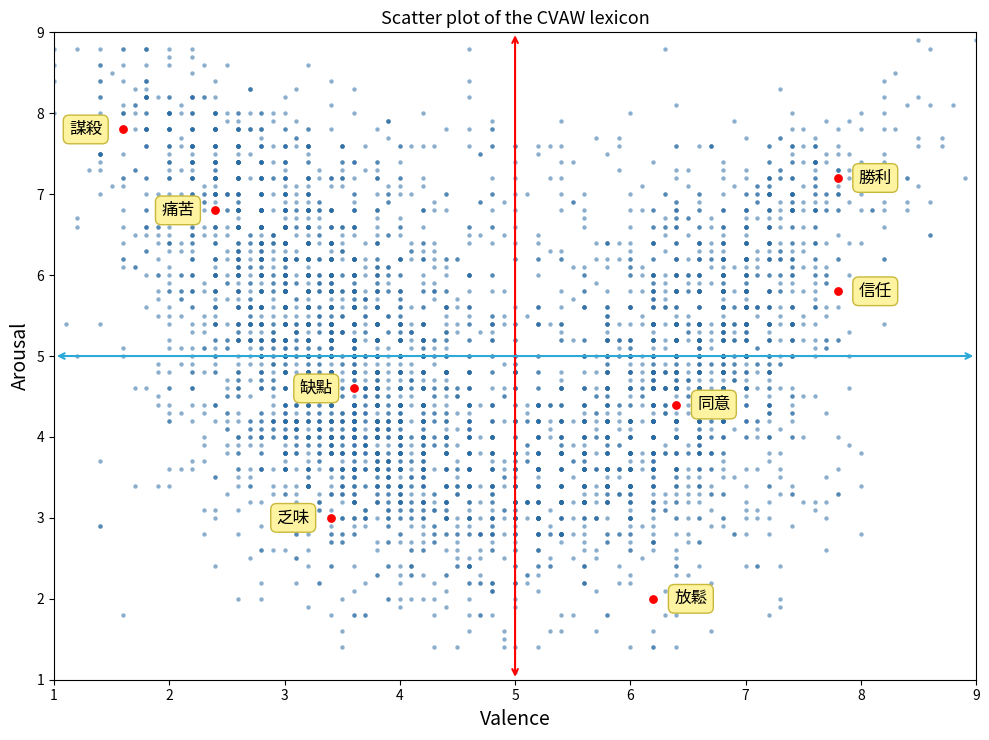

已標註的詞: {'同意', '放鬆', '缺點', '謀殺', '乏味', '信任', '痛苦', '勝利'}


In [7]:
LABEL_WORDS = [
    ('謀殺', (-15, 0),  (1.6, 8.0)),   # 左上：高激發、負向
    ('痛苦', (-15, 0),  (2.0, 6.8)),
    ('勝利', (15, 0),   (7.8, 7.0)),   # 右上：高激發、正向
    ('信任', (15, 0),   (7.8, 5.7)),
    ('缺點', (-15, 0),  (3.6, 4.5)),   # 中間偏負
    ('同意', (15, 0),   (6.4, 4.3)),   # 中間偏正
    ('乏味', (-15, 0),  (2.5, 3.0)),   # 左下：低激發、負向
    ('放鬆', (15, 0),   (6.3, 2.0)),   # 右下：低激發、正向
]


def _nearest_word(df, target_v, target_a, exclude=set()):
    d = (df['Valence_Mean'] - target_v) ** 2 + (df['Arousal_Mean'] - target_a) ** 2
    d[df['Word'].isin(exclude)] = np.inf
    idx = d.idxmin()
    return df.loc[idx, 'Word'], df.loc[idx, 'Valence_Mean'], df.loc[idx, 'Arousal_Mean']


def plot_cvaw_scatter(df):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(df['Valence_Mean'], df['Arousal_Mean'],
               s=10, color='#2b6ca3', alpha=0.55, linewidths=0, zorder=2)
    ax.annotate('', xy=(5, 9), xytext=(5, 1),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5), zorder=3)
    ax.annotate('', xy=(9, 5), xytext=(1, 5),
                arrowprops=dict(arrowstyle='<->', color='#2ca9d6', lw=1.5), zorder=3)

    used_words = set()
    for word, offset, fallback_xy in LABEL_WORDS:
        row = df[df['Word'] == word]
        if len(row):
            v, a = row.iloc[0]['Valence_Mean'], row.iloc[0]['Arousal_Mean']
            label = word
        else:
            label, v, a = _nearest_word(df, *fallback_xy, exclude=used_words)
        used_words.add(label)
        ax.scatter([v], [a], s=28, color='red', zorder=4)
        ax.annotate(label, xy=(v, a), xytext=offset, textcoords='offset points',
                    fontsize=12, va='center',
                    ha='right' if offset[0] < 0 else 'left',
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdf3a0',
                              edgecolor='#c9b93a', linewidth=1),
                    zorder=5)

    ax.set_xlim(1, 9); ax.set_ylim(1, 9)
    ax.set_xlabel('Valence', fontsize=14)
    ax.set_ylabel('Arousal', fontsize=14)
    ax.set_title('Scatter plot of the CVAW lexicon', fontsize=13)
    plt.tight_layout()
    plt.savefig('cvaw_scatter.png', dpi=200)
    plt.show()
    print('已標註的詞:', used_words)


plot_cvaw_scatter(cvaw)

## [新增] 通用版 VA 散佈圖工具（給 NNword / NNmod / NNsent 預測結果用）

In [8]:
VA_SCATTER_ANCHORS = [
    ((-15, 0), (1.6, 8.0)),
    ((-15, 0), (2.0, 6.8)),
    ((15, 0),  (7.8, 7.0)),
    ((15, 0),  (7.8, 5.7)),
    ((-15, 0), (3.6, 4.5)),
    ((15, 0),  (6.4, 4.3)),
    ((-15, 0), (2.5, 3.0)),
    ((15, 0),  (6.3, 2.0)),
]


def _nearest_item(vs, as_, texts, target_v, target_a, exclude):
    d = (vs - target_v) ** 2 + (as_ - target_a) ** 2
    d = d.copy()
    for i in exclude:
        d[i] = np.inf
    idx = int(np.argmin(d))
    return idx, vs[idx], as_[idx], texts[idx]


def plot_va_scatter(values_v, values_a, texts, title, savepath=None, max_len=10):
    """
    values_v / values_a：模型輸出的正規化 [0,1] VA 陣列，自動還原成 1-9 分數畫圖。
    texts：對應每個點的原文字（詞／短語／句子），自動挑離八個象限錨點最近的
           實際樣本標註，不用手動指定詞表。
    """
    vs = np.asarray(values_v, dtype=np.float64) * 8 + 1
    as_ = np.asarray(values_a, dtype=np.float64) * 8 + 1
    texts = list(texts)

    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(vs, as_, s=10, color='#2b6ca3', alpha=0.45, linewidths=0, zorder=2)
    ax.annotate('', xy=(5, 9), xytext=(5, 1),
                arrowprops=dict(arrowstyle='<->', color='red', lw=1.5), zorder=3)
    ax.annotate('', xy=(9, 5), xytext=(1, 5),
                arrowprops=dict(arrowstyle='<->', color='#2ca9d6', lw=1.5), zorder=3)

    used = set()
    for offset, (tv, ta) in VA_SCATTER_ANCHORS:
        idx, v, a, txt = _nearest_item(vs, as_, texts, tv, ta, used)
        used.add(idx)
        label = txt if len(txt) <= max_len else txt[:max_len] + '…'
        ax.scatter([v], [a], s=28, color='red', zorder=4)
        ax.annotate(label, xy=(v, a), xytext=offset, textcoords='offset points',
                    fontsize=11, va='center',
                    ha='right' if offset[0] < 0 else 'left',
                    bbox=dict(boxstyle='round,pad=0.35', facecolor='#fdf3a0',
                              edgecolor='#c9b93a', linewidth=1),
                    zorder=5)

    ax.set_xlim(1, 9); ax.set_ylim(1, 9)
    ax.set_xlabel('Valence', fontsize=14)
    ax.set_ylabel('Arousal', fontsize=14)
    ax.set_title(title, fontsize=13)
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=200)
    plt.show()


print('plot_va_scatter 定義完成（NNword / NNmod / NNsent 共用）')

plot_va_scatter 定義完成（NNword / NNmod / NNsent 共用）


## 2. 資料前處理
v7-2 進一步加入否定詞範圍規則（例如「不是很」「並不太」），
提升複合修飾詞切割的穩定性，減少誤切。

In [9]:
def normalize_va(df, val_col='Valence_Mean', aro_col='Arousal_Mean'):
    df = df.copy()
    df[val_col] = pd.to_numeric(df[val_col], errors='coerce')
    df[aro_col] = pd.to_numeric(df[aro_col], errors='coerce')
    before = len(df)
    df = df.dropna(subset=[val_col, aro_col]).reset_index(drop=True)
    if before - len(df) > 0:
        print(f'  ⚠ 清除 {before-len(df)} 筆髒資料')
    df['valence'] = (df[val_col] - 1) / 8.0
    df['arousal'] = (df[aro_col] - 1) / 8.0
    return df
cvaw = normalize_va(cvaw)
cvap = normalize_va(cvap)
cvas = normalize_va(cvas)
# CVAP 短語切割：由右向左找核心詞 + 否定詞範圍規則
cvaw_word_set = set(cvaw['Word'].astype(str).tolist())
max_core_len = max(len(w) for w in cvaw_word_set)
# 否定詞與程度詞（長詞優先匹配）
NEGATION_CUES = {
    '不是很', '並不太', '並不是', '不怎麼', '不太', '不是', '並不', '沒有', '沒', '不', '無', '未', '別', '勿'
}
DEGREE_CUES = {
    '超級', '極為', '非常', '相當', '十分', '更加', '格外', '特別', '有點', '稍微', '很', '太', '更', '極', '超'
}
# 常見多詞修飾鏈，優先整體匹配
COMPOSITE_MODIFIERS = {
    '不是很', '並不太', '並不是很', '沒有很', '不怎麼', '不太'
}
MODIFIER_LEXICON = sorted(
    COMPOSITE_MODIFIERS | NEGATION_CUES | DEGREE_CUES,
    key=len,
    reverse=True
)
def normalize_text(s):
    s = str(s).strip()
    for ch in '，。！？、,.!?;；：「」『』（）() ':
        s = s.replace(ch, '')
    return s
def split_modifier_chain(modifier_text):
    """
    規則切分：
    1) 優先匹配複合否定程度詞（如 不是很/並不太）
    2) 次優先匹配一般否定或程度詞
    3) 未知片段退回單字，避免直接丟失資訊
    """
    txt = normalize_text(modifier_text)
    if not txt:
        return []
    mods = []
    i = 0
    while i < len(txt):
        matched = None
        for tok in MODIFIER_LEXICON:
            if txt.startswith(tok, i):
                matched = tok
                break
        if matched is None:
            matched = txt[i:i+1]
        mods.append(matched)
        i += len(matched)
    # 後處理：若出現「不是 + 很」「並不 + 太」再合併回範圍詞
    merged = []
    j = 0
    while j < len(mods):
        if j + 1 < len(mods):
            pair = mods[j] + mods[j + 1]
            if pair in COMPOSITE_MODIFIERS:
                merged.append(pair)
                j += 2
                continue
        merged.append(mods[j])
        j += 1
    return merged
def split_phrase(phrase, cvaw_words):
    phrase = normalize_text(phrase)
    candidates = []
    upper = min(max_core_len, len(phrase) - 1)
    for core_len in range(upper, 0, -1):
        core = phrase[-core_len:]
        modifier = phrase[:-core_len]
        if core in cvaw_words and len(modifier) > 0:
            mod_tokens = split_modifier_chain(modifier)
            neg_hits = sum(t in NEGATION_CUES for t in mod_tokens)
            deg_hits = sum(t in DEGREE_CUES for t in mod_tokens)
            # 先偏好含關鍵修飾詞，再偏好較長核心詞
            score = (neg_hits + deg_hits, neg_hits, core_len)
            candidates.append((score, modifier, core, mod_tokens))
    if candidates:
        _, modifier, core, mod_tokens = max(candidates, key=lambda x: x[0])
        return modifier, core, mod_tokens
    return None, None, []
mods, cores, mod_chains = [], [], []
for phrase in cvap['Phrase']:
    m, c, chain = split_phrase(phrase, cvaw_word_set)
    mods.append(m)
    cores.append(c)
    mod_chains.append(chain)
cvap['modifier'] = mods
cvap['core_word'] = cores
cvap['modifier_chain'] = mod_chains
cvap_aligned = cvap.dropna(subset=['modifier', 'core_word']).copy()
print(f'CVAP 對齊: {len(cvap_aligned)} / {len(cvap)} 筆')
print('切割示例（前 5 筆）:')
print(cvap_aligned[['Phrase', 'modifier', 'core_word', 'modifier_chain']].head().to_string(index=False))
# 8:2 切分
cvaw_train, cvaw_test = train_test_split(cvaw,         test_size=0.2, random_state=42)
# v8-UniCtx2：從訓練集再切 15% 當 NNword 的驗證集（只用來 early stopping / 看過擬合，不參與梯度更新）
cvaw_train, cvaw_val  = train_test_split(cvaw_train,  test_size=0.15, random_state=42)
cvap_train, cvap_test = train_test_split(cvap_aligned, test_size=0.2, random_state=42)
print(f'CVAW 訓練:{len(cvaw_train)}  驗證:{len(cvaw_val)}  測試:{len(cvaw_test)}')
print(f'CVAP 訓練:{len(cvap_train)}  測試:{len(cvap_test)}')

CVAP 對齊: 2249 / 2250 筆
切割示例（前 5 筆）:
Phrase modifier core_word modifier_chain
   怪八卦        怪        八卦            [怪]
  更加小心       更加        小心           [更加]
  格外小心       格外        小心           [格外]
  特別小心       特別        小心           [特別]
  極為小心       極為        小心           [極為]
CVAW 訓練:3747  驗證:662  測試:1103
CVAP 訓練:1799  測試:450


In [10]:
# 規則切割 sanity check（否定詞範圍）
probe_phrases = [
    '不是很開心',
    '並不太滿意',
    '不怎麼快樂',
    '沒有很失望',
    '非常開心',
]
print('=== Modifier Scope Sanity Check ===')
for p in probe_phrases:
    m, c, chain = split_phrase(p, cvaw_word_set)
    print(f'{p:8s} -> modifier={m}, core={c}, chain={chain}')

=== Modifier Scope Sanity Check ===
不是很開心    -> modifier=不是很, core=開心, chain=['不是很']
並不太滿意    -> modifier=並不太, core=滿意, chain=['並不太']
不怎麼快樂    -> modifier=不怎麼, core=快樂, chain=['不怎麼']
沒有很失望    -> modifier=沒有很, core=失望, chain=['沒有很']
非常開心     -> modifier=非常, core=開心, chain=['非常']


## 3. 載入中文 BERT
v7-2 除了單詞向量，也新增「修飾詞 + 被修飾詞」的 pair 向量：  
`BERT(modifier [SEP] target_text)`，讓 NNmod 具備語境感知能力。

In [11]:
BERT_NAME = 'hfl/chinese-bert-wwm-ext'
print(f'載入 {BERT_NAME}（約需 1~2 分鐘）...')
tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert_model = AutoModel.from_pretrained(BERT_NAME).to(device)
BERT_DIM = bert_model.config.hidden_size
print(f'✅ 載入完成 | hidden size: {BERT_DIM}')
@torch.no_grad()
def get_bert_vec(text):
    """
    單輸入 BERT [CLS]。
    用於核心詞的 base 情緒表示。
    """
    bert_model.eval()
    enc = tokenizer(
        text, return_tensors='pt',
        padding=True, truncation=True, max_length=16
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
@torch.no_grad()
def get_bert_pair_vec(modifier, target_text):
    """
    語境化修飾詞向量：BERT(modifier [SEP] target_text)
    讓 NNmod 感知修飾詞正在修飾哪個詞/片語。
    """
    bert_model.eval()
    enc = tokenizer(
        modifier,
        target_text,
        return_tensors='pt',
        padding=True,
        truncation=True,
        max_length=24
    ).to(device)
    out = bert_model(**enc)
    cls_vec = out.last_hidden_state[:, 0, :].squeeze(0)
    return cls_vec.cpu().numpy().astype(np.float32)
# 批次版本（訓練時效率更高）
@torch.no_grad()
def get_bert_vecs_batch(texts, batch_size=64):
    bert_model.eval()
    all_vecs = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size]
        enc = tokenizer(
            batch, return_tensors='pt',
            padding=True, truncation=True, max_length=16
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
@torch.no_grad()
def get_bert_pair_vecs_batch(modifiers, targets, batch_size=64):
    bert_model.eval()
    all_vecs = []
    n = len(modifiers)
    for i in range(0, n, batch_size):
        b_mod = modifiers[i:i+batch_size]
        b_tgt = targets[i:i+batch_size]
        enc = tokenizer(
            b_mod,
            b_tgt,
            return_tensors='pt',
            padding=True,
            truncation=True,
            max_length=24
        ).to(device)
        out = bert_model(**enc)
        cls = out.last_hidden_state[:, 0, :]
        all_vecs.append(cls.cpu().numpy())
    return np.concatenate(all_vecs, axis=0).astype(np.float32)
# 測試
v1 = get_bert_vec('開心')
v2 = get_bert_vec('難過')
pair_v = get_bert_pair_vec('非常', '開心')
sim_happy_sad = float(np.dot(v1, v2) / (np.linalg.norm(v1) * np.linalg.norm(v2)))
print(f'開心 vs 難過 cosine: {sim_happy_sad:.4f}')
print(f'BERT 向量維度: {v1.shape} | pair 向量維度: {pair_v.shape}')

載入 hfl/chinese-bert-wwm-ext（約需 1~2 分鐘）...


config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/19.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/110k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/269k [00:00<?, ?B/s]

...

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  412MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: hfl/chinese-bert-wwm-ext
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ 載入完成 | hidden size: 768
開心 vs 難過 cosine: 0.8179
BERT 向量維度: (768,) | pair 向量維度: (768,)


## 4. 模型定義
### NNword head：BERT 向量 → VA 值
維持單詞基準情緒估計。
### NNmod：語境化修飾 + V/A 互動
輸入改為 `BERT(modifier [SEP] target_text)`，並加入 `v, a, v*a, v-a` 互動特徵，
讓 Valence/Arousal 的偏移可共享語意表示、降低獨立建模限制。

In [12]:
class NNword(nn.Module):
    """
    v8-UniCtx2 版 NNword：BERT [CLS] → (微調層 adapter) → Valence / Arousal
    輸入：BERT 768 維向量（單詞，BERT 本身凍結）
    輸出：val, aro ∈ [0,1]

    相對 v7-2 的改動：在「BERT 向量」與「VA 預測頭」之間插入一層可訓練的微調層（residual adapter）
        h = x + Up( Dropout( ReLU( Down( LayerNorm(Dropout(x)) ) ) ) )
      - BERT [CLS] 原本不是為「情緒強度」訓練的；adapter 負責把向量轉成適合 VA 的表示。
      - Up 層零初始化 → 剛開始 h = x（等於 v7-2 的行為），不會比原本更差。
      - Dropout：輸入端 p_in、adapter 內 p_ad、預測頭內 p_head；L2 / L1 在訓練迴圈（見 Stage 1 訓練 cell）。
    NNmod 對 NNword 的呼叫介面（forward 回傳 (val, aro)）完全不變。
    """
    def __init__(self, bert_dim=768, adapter_dim=256, p_in=0.2, p_ad=0.2, p_head=0.3):
        super().__init__()
        self.in_drop = nn.Dropout(p_in)
        self.ad_norm = nn.LayerNorm(bert_dim)
        self.ad_down = nn.Linear(bert_dim, adapter_dim)
        self.ad_drop = nn.Dropout(p_ad)
        self.ad_up   = nn.Linear(adapter_dim, bert_dim)
        nn.init.zeros_(self.ad_up.weight)
        nn.init.zeros_(self.ad_up.bias)
        self.head = nn.Sequential(
            nn.Linear(bert_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(p_head),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def adapt(self, bert_vec):
        x = self.in_drop(bert_vec)
        return x + self.ad_up(self.ad_drop(torch.relu(self.ad_down(self.ad_norm(x)))))

    def forward(self, bert_vec):
        out = torch.sigmoid(self.head(self.adapt(bert_vec)))
        return out[:, 0:1], out[:, 1:2]


class NNmod(nn.Module):
    """
    v7-2 版 NNmod：語境化修飾 + V/A 互動建模
    輸入：
      1) Int_val(w), Int_aro(w)
      2) BERT(modifier [SEP] target_text) 的語境向量
    設計重點：
      - delta 由 shared hidden 同時決定 val/aro（共享表示，允許耦合）
      - 加入 [v, a, v*a, v-a] 互動特徵
      - 回傳 c_mod_v / c_mod_a，便於雙維度分析
      - 使用 LayerNorm 以支援遞迴鏈訓練時的 batch size=1
    """
    def __init__(self, bert_dim=768):
        super().__init__()
        feat_dim = bert_dim + 4
        self.fc1 = nn.Linear(feat_dim, 192)
        self.fc2 = nn.Linear(192, 64)
        self.fc3 = nn.Linear(64, 2)
        self.ln1 = nn.LayerNorm(192)
        self.ln2 = nn.LayerNorm(64)
        self.drop = nn.Dropout(0.1)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    def forward(self, int_val, int_aro, bert_mod_ctx):
        va_feat = torch.cat([
            int_val,
            int_aro,
            int_val * int_aro,
            int_val - int_aro
        ], dim=1)
        x = torch.cat([bert_mod_ctx, va_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        delta_v = delta[:, 0:1]
        delta_a = delta[:, 1:2]
        out_v = torch.sigmoid(torch.logit(int_val.clamp(0.01, 0.99)) + delta_v * 3)
        out_a = torch.sigmoid(torch.logit(int_aro.clamp(0.01, 0.99)) + delta_a * 3)
        c_mod_v = delta_v + 0.5
        c_mod_a = delta_a + 0.5
        return out_v, out_a, c_mod_v, c_mod_a
print('NNword / NNmod（v7-2）定義完成')

NNword / NNmod（v7-2）定義完成


## 5. 預先計算所有 BERT 向量（含遞迴鏈）
除了 core word 向量，也快取遞迴鏈每一步需要的 pair context 向量：  
`modifier [SEP] current_phrase`，供 Stage 2 直接訓練多層遞迴鏈。

In [13]:
print('預先計算 CVAW 訓練集詞向量...')
word_train_vecs = get_bert_vecs_batch(cvaw_train['Word'].tolist())
word_train_val  = cvaw_train['valence'].values.astype(np.float32)
word_train_aro  = cvaw_train['arousal'].values.astype(np.float32)
print('預先計算 CVAW 測試集詞向量...')
word_test_vecs  = get_bert_vecs_batch(cvaw_test['Word'].tolist())
word_test_val   = cvaw_test['valence'].values.astype(np.float32)
word_test_aro   = cvaw_test['arousal'].values.astype(np.float32)
print('預先計算 CVAW 驗證集詞向量...')
word_val_vecs   = get_bert_vecs_batch(cvaw_val['Word'].tolist())
word_val_val    = cvaw_val['valence'].values.astype(np.float32)
word_val_aro    = cvaw_val['arousal'].values.astype(np.float32)
print('建立遞迴鏈訓練樣本（含 context cache）...')
core_cache = {}
pair_cache = {}
def get_core_vec_cached(word):
    if word not in core_cache:
        core_cache[word] = get_bert_vec(word)
    return core_cache[word]
def get_pair_vec_cached(modifier, target):
    key = (modifier, target)
    if key not in pair_cache:
        pair_cache[key] = get_bert_pair_vec(modifier, target)
    return pair_cache[key]
def build_recursive_chain_samples(df):
    samples = []
    for _, row in df.iterrows():
        core = str(row['core_word'])
        chain = row['modifier_chain'] if isinstance(row['modifier_chain'], list) else []
        if len(chain) == 0:
            chain = [str(row['modifier'])]
        cur_phrase = core
        ctx_chain = []
        # 由最靠近核心詞者先作用，因此反向展開
        for mod in reversed(chain):
            mod = str(mod)
            ctx_chain.append(get_pair_vec_cached(mod, cur_phrase))
            cur_phrase = mod + cur_phrase
        samples.append({
            'core_word': core,
            'full_phrase': str(row['Phrase']),
            'mods_outer_to_inner': chain,
            'ctx_chain': ctx_chain,
            'core_vec': get_core_vec_cached(core),
            'valence': float(row['valence']),
            'arousal': float(row['arousal']),
        })
    return samples
train_chain_samples = build_recursive_chain_samples(cvap_train)
test_chain_samples  = build_recursive_chain_samples(cvap_test)
# 保留舊變數名稱方便後續 cell 相容
core_train_vecs = np.stack([s['core_vec'] for s in train_chain_samples]).astype(np.float32)
core_test_vecs  = np.stack([s['core_vec'] for s in test_chain_samples]).astype(np.float32)
phrase_train_val = np.array([s['valence'] for s in train_chain_samples], dtype=np.float32)
phrase_train_aro = np.array([s['arousal'] for s in train_chain_samples], dtype=np.float32)
phrase_test_val  = np.array([s['valence'] for s in test_chain_samples], dtype=np.float32)
phrase_test_aro  = np.array([s['arousal'] for s in test_chain_samples], dtype=np.float32)
# Stage 1 張量（維持不變）
wt_v = torch.tensor(word_train_vecs).to(device)
wt_y_v = torch.tensor(word_train_val).unsqueeze(1).to(device)
wt_y_a = torch.tensor(word_train_aro).unsqueeze(1).to(device)
chain_lens = np.array([len(s['ctx_chain']) for s in train_chain_samples])
print(f'詞訓練: {wt_v.shape}')
print(f'遞迴鏈訓練樣本: {len(train_chain_samples)}  測試樣本: {len(test_chain_samples)}')
print(f'訓練鏈長度: mean={chain_lens.mean():.2f}, max={chain_lens.max()}, min={chain_lens.min()}')
print(f'cache | core: {len(core_cache)}  pair: {len(pair_cache)}')

預先計算 CVAW 訓練集詞向量...
預先計算 CVAW 測試集詞向量...
預先計算 CVAW 驗證集詞向量...
建立遞迴鏈訓練樣本（含 context cache）...
詞訓練: torch.Size([3747, 768])
遞迴鏈訓練樣本: 1799  測試樣本: 450
訓練鏈長度: mean=1.97, max=4, min=1
cache | core: 335  pair: 3387


## 6. Stage 1：訓練 NNword（BERT 向量 → VA）

=== Stage 1：訓練 NNword（BERT → 微調層 → VA；dropout + L1/L2）===
Epoch  10/50 | train MSE: 0.012973 | val MSE: 0.013524
Epoch  20/50 | train MSE: 0.010771 | val MSE: 0.013427
  early stop @ epoch 24（驗證集 loss 連續 10 epoch 沒進步）
還原最佳 epoch = 14（val MSE = 0.013317）


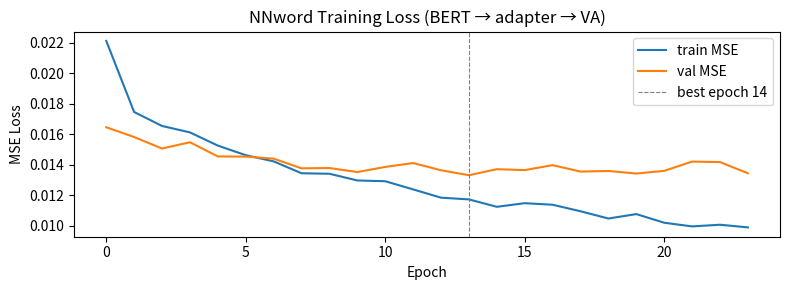

NNword Pearson r (V / A)：
  train 0.9346 / 0.8328
  val   0.8900 / 0.6520
  test  0.8745 / 0.6320
  train−test 落差：V +0.0601 / A +0.2009（落差越小代表過擬合越輕）
Stage 1 完成


In [14]:
from torch.utils.data import TensorDataset, DataLoader
import copy, random

# ---- v8-UniCtx2：NNword（含微調層）訓練設定 ----
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

NNWORD_L2   = 0.05      # L2：AdamW 的 decoupled weight decay（v7-2 是 0.01）
NNWORD_L1   = 1e-6      # L1：對所有權重矩陣 (dim>=2) 加 L1 * Σ|w|（只加在 adapter + 預測頭的權重，不含 bias / BN）
N_EPOCHS_WORD = 50
USE_EARLY_STOP_WORD = True   # 以「驗證集 loss」選最佳 epoch，還原該 epoch 的權重
PATIENCE_WORD = 10

model_word = NNword(BERT_DIM).to(device)
opt_word   = optim.AdamW(model_word.parameters(), lr=1e-3, weight_decay=NNWORD_L2)
sch_word   = optim.lr_scheduler.StepLR(opt_word, step_size=30, gamma=0.5)

wv_v   = torch.tensor(word_val_vecs).to(device)
wv_y_v = torch.tensor(word_val_val).unsqueeze(1).to(device)
wv_y_a = torch.tensor(word_val_aro).unsqueeze(1).to(device)

# DataLoader（batch training 讓 BatchNorm 正常運作）
word_ds = TensorDataset(wt_v, wt_y_v, wt_y_a)
word_dl = DataLoader(word_ds, batch_size=64, shuffle=True)

def _l1_word(model):
    return sum(p.abs().sum() for p in model.parameters() if p.dim() >= 2)

@torch.no_grad()
def _eval_word(model, X, yv, ya):
    model.eval()
    pv, pa = model(X)
    return (0.5 * ((pv - yv)**2 + (pa - ya)**2).mean()).item()

print('=== Stage 1：訓練 NNword（BERT → 微調層 → VA；dropout + L1/L2）===')
losses_w, val_losses_w = [], []
best_val_w, best_ep_w, best_state_w, bad_w = float('inf'), 0, None, 0
for epoch in range(N_EPOCHS_WORD):
    model_word.train()
    epoch_loss = 0.0
    for bvec, by_v, by_a in word_dl:
        pred_v, pred_a = model_word(bvec)
        mse  = 0.5 * ((pred_v - by_v)**2 + (pred_a - by_a)**2).mean()
        loss = mse + NNWORD_L1 * _l1_word(model_word)
        opt_word.zero_grad()
        loss.backward()
        opt_word.step()
        epoch_loss += mse.item()
    sch_word.step()
    avg = epoch_loss / len(word_dl)
    vl  = _eval_word(model_word, wv_v, wv_y_v, wv_y_a)
    losses_w.append(avg); val_losses_w.append(vl)
    if vl < best_val_w - 1e-6:
        best_val_w, best_ep_w, bad_w = vl, epoch + 1, 0
        best_state_w = copy.deepcopy(model_word.state_dict())
    else:
        bad_w += 1
    if (epoch+1) % 10 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_WORD} | train MSE: {avg:.6f} | val MSE: {vl:.6f}')
    if USE_EARLY_STOP_WORD and bad_w >= PATIENCE_WORD:
        print(f'  early stop @ epoch {epoch+1}（驗證集 loss 連續 {PATIENCE_WORD} epoch 沒進步）')
        break

if USE_EARLY_STOP_WORD and best_state_w is not None:
    model_word.load_state_dict(best_state_w)
    print(f'還原最佳 epoch = {best_ep_w}（val MSE = {best_val_w:.6f}）')
model_word.eval()

plt.figure(figsize=(8,3))
plt.plot(losses_w, label='train MSE')
plt.plot(val_losses_w, label='val MSE')
plt.axvline(best_ep_w - 1, color='gray', ls='--', lw=0.8, label=f'best epoch {best_ep_w}')
plt.title('NNword Training Loss (BERT → adapter → VA)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss'); plt.legend()
plt.tight_layout(); plt.show()

# ---- 過擬合診斷：train / val / test 的 Pearson r 與落差 ----
@torch.no_grad()
def _word_r(X, yv, ya):
    model_word.eval()
    pv, pa = model_word(X)
    return (float(pearsonr(pv.cpu().numpy().ravel(), yv.cpu().numpy().ravel())[0]),
            float(pearsonr(pa.cpu().numpy().ravel(), ya.cpu().numpy().ravel())[0]))
_wte_v   = torch.tensor(word_test_vecs).to(device)
_wte_y_v = torch.tensor(word_test_val).unsqueeze(1).to(device)
_wte_y_a = torch.tensor(word_test_aro).unsqueeze(1).to(device)
_r_tr, _r_va, _r_te = _word_r(wt_v, wt_y_v, wt_y_a), _word_r(wv_v, wv_y_v, wv_y_a), _word_r(_wte_v, _wte_y_v, _wte_y_a)
print('NNword Pearson r (V / A)：')
print(f'  train {_r_tr[0]:.4f} / {_r_tr[1]:.4f}')
print(f'  val   {_r_va[0]:.4f} / {_r_va[1]:.4f}')
print(f'  test  {_r_te[0]:.4f} / {_r_te[1]:.4f}')
print(f'  train−test 落差：V {_r_tr[0]-_r_te[0]:+.4f} / A {_r_tr[1]-_r_te[1]:+.4f}'
      '（落差越小代表過擬合越輕）')
print('Stage 1 完成')

## 7. Stage 2：訓練 NNmod（NNword 凍結，直接訓練遞迴鏈）
**v7-2 遞迴鏈訓練流程：**
1. NNword(BERT(core_word)) → Int(w)
2. 由最靠近核心詞的修飾詞開始，逐層遞迴：
   NNmod(Int(current), BERT(modifier [SEP] current_phrase))
3. 以最終 Int(full_phrase) 對齊片語標註 VA
NNword 仍凍結，只訓練 NNmod；但現在訓練時就會展開多層鏈。

=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===
流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)
Epoch  20/100 | Loss: 0.004289
Epoch  40/100 | Loss: 0.002442
Epoch  60/100 | Loss: 0.001758
Epoch  80/100 | Loss: 0.001519
Epoch 100/100 | Loss: 0.001543


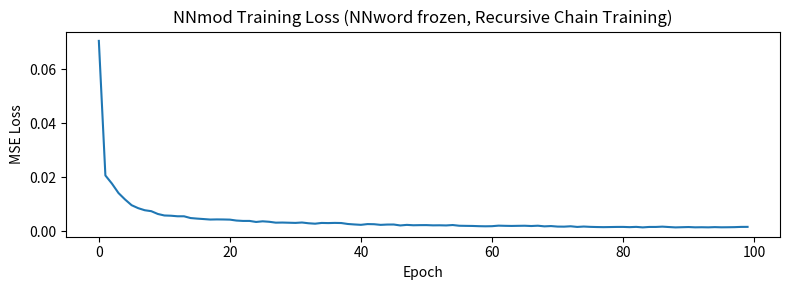

Stage 2 完成


In [15]:
model_mod = NNmod(BERT_DIM).to(device)
# 凍結 NNword
for param in model_word.parameters():
    param.requires_grad = False
opt_mod = optim.AdamW(model_mod.parameters(), lr=3e-3, weight_decay=1e-4)
print('=== Stage 2：訓練 NNmod（NNword 凍結，直接遞迴鏈訓練）===')
print('流程：BERT(core) → NNword → Int(w) → NNmod(遞迴多步) → Int(full phrase)')
N_EPOCHS_MOD = 100
losses_m = []
grad_accum_steps = 16
for epoch in range(N_EPOCHS_MOD):
    model_mod.train()
    model_word.eval()
    epoch_loss = 0.0
    idxs = np.random.permutation(len(train_chain_samples))
    opt_mod.zero_grad()
    for step_i, si in enumerate(idxs, start=1):
        s = train_chain_samples[si]
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        # Step 1：核心詞先經 NNword（固定）
        with torch.no_grad():
            cur_v, cur_a = model_word(core_t)
        # Step 2：沿遞迴鏈逐步套用 NNmod（每步語境都不同）
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, _ = model_mod(cur_v, cur_a, ctx_t)
        # 只用最終 full phrase 監督
        loss = 0.5 * ((cur_v - y_v)**2 + (cur_a - y_a)**2).mean()
        (loss / grad_accum_steps).backward()
        epoch_loss += loss.item()
        if (step_i % grad_accum_steps == 0) or (step_i == len(idxs)):
            torch.nn.utils.clip_grad_norm_(model_mod.parameters(), max_norm=1.0)
            opt_mod.step()
            opt_mod.zero_grad()
    avg = epoch_loss / len(train_chain_samples)
    losses_m.append(avg)
    if (epoch + 1) % 20 == 0:
        print(f'Epoch {epoch+1:3d}/{N_EPOCHS_MOD} | Loss: {avg:.6f}')
plt.figure(figsize=(8,3))
plt.plot(losses_m)
plt.title('NNmod Training Loss (NNword frozen, Recursive Chain Training)')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.tight_layout(); plt.show()
print('Stage 2 完成')

## 8. 預測函式

In [16]:
@torch.no_grad()
def predict_word_va(word):
    """
    單詞 VA 預測：BERT encode → NNword → (valence, arousal)
    """
    model_word.eval()
    vec = torch.tensor(get_bert_vec(word)).unsqueeze(0).to(device)
    val, aro = model_word(vec)
    return val.item(), aro.item()
@torch.no_grad()
def predict_phrase_va_pipeline(modifier, core_word, verbose=False):
    """
    單層 Pipeline 預測（語境化修飾詞）：
    BERT(core_word) → NNword → Int(w)
    BERT(modifier [SEP] core_word) → NNmod → Int(mod w)
    """
    model_word.eval()
    model_mod.eval()
    # Step 1：核心詞 BERT encode → NNword → Int(w)
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    int_val, int_aro = model_word(core_vec)
    # Step 2：語境化修飾詞 BERT encode → NNmod
    mod_ctx_vec = torch.tensor(get_bert_pair_vec(modifier, core_word)).unsqueeze(0).to(device)
    pred_v, pred_a, c_mod_v, c_mod_a = model_mod(int_val, int_aro, mod_ctx_vec)
    pv, pa = pred_v.item(), pred_a.item()
    iv, ia = int_val.item(), int_aro.item()
    cmv = c_mod_v.item()
    cma = c_mod_a.item()
    if verbose:
        print(f'「{modifier}{core_word}」'
              f'  base(V={iv:.3f},A={ia:.3f})'
              f'  Cmod(V={cmv:.3f},A={cma:.3f})'
              f'  → V={pv:.4f} A={pa:.4f}')
    return pv, pa, cmv, cma
def va_label(v, a):
    pol = '正向' if v>=0.625 else ('負向' if v<=0.375 else '中性')
    act = '高喚起' if a>=0.625 else ('低喚起' if a<=0.375 else '中喚起')
    return f'{pol}/{act}'
# 測試預測
print('=== 單詞預測 ===')
for w in ['開心','難過','憤怒','平靜','興奮','恐懼']:
    v, a = predict_word_va(w)
    print(f'「{w}」V={v:.4f} A={a:.4f} → {va_label(v,a)}')
print()
print('=== Pipeline 片語預測 ===')
for mod, word in [('非常','開心'),('沒有','希望'),('完全','不滿意'),
                  ('極為','不安'),('相當','平靜'),('可能','失望')]:
    pv, pa, cmv, cma = predict_phrase_va_pipeline(mod, word, verbose=True)
    print(f'  → {va_label(pv, pa)} | Cmod(V={cmv:.3f}, A={cma:.3f})')

=== 單詞預測 ===
「開心」V=0.8080 A=0.6279 → 正向/高喚起
「難過」V=0.3205 A=0.5465 → 負向/中喚起
「憤怒」V=0.2099 A=0.8780 → 負向/高喚起
「平靜」V=0.6389 A=0.1728 → 正向/低喚起
「興奮」V=0.7966 A=0.7760 → 正向/高喚起
「恐懼」V=0.2470 A=0.7338 → 負向/高喚起

=== Pipeline 片語預測 ===
「非常開心」  base(V=0.808,A=0.628)  Cmod(V=0.722,A=0.839)  → V=0.8912 A=0.8236
  → 正向/高喚起 | Cmod(V=0.722, A=0.839)
「沒有希望」  base(V=0.729,A=0.542)  Cmod(V=0.001,A=0.464)  → V=0.3758 A=0.5146
  → 中性/中喚起 | Cmod(V=0.001, A=0.464)
「完全不滿意」  base(V=0.418,A=0.404)  Cmod(V=0.182,A=0.694)  → V=0.2168 A=0.5482
  → 負向/中喚起 | Cmod(V=0.182, A=0.694)
「極為不安」  base(V=0.422,A=0.504)  Cmod(V=0.186,A=0.756)  → V=0.2219 A=0.6869
  → 負向/高喚起 | Cmod(V=0.186, A=0.756)
「相當平靜」  base(V=0.639,A=0.173)  Cmod(V=0.613,A=0.579)  → V=0.7131 A=0.2096
  → 正向/低喚起 | Cmod(V=0.613, A=0.579)
「可能失望」  base(V=0.299,A=0.545)  Cmod(V=0.340,A=0.503)  → V=0.2087 A=0.5466
  → 負向/中喚起 | Cmod(V=0.340, A=0.503)


## 9. 多修飾詞遞迴預測（論文 Fig. 4）
每層輸出 VA 傳入下一層，逐層套用修飾詞。  
v7-2 在每一層都用 `BERT(modifier [SEP] 當前片語)` 重新編碼，
避免同一個副詞在不同語境得到完全相同表示。

In [17]:
@torch.no_grad()
def predict_multi_mod_pipeline(modifiers, core_word):
    """
    多修飾詞遞迴 Pipeline（對應論文 Fig. 4）：
    由最靠近核心詞的修飾詞（列表最右）開始，逐層向外套用。
    語境化版本：每層使用 BERT(modifier [SEP] 當前片語)
    """
    model_word.eval()
    model_mod.eval()
    phrase_str = ''.join(modifiers) + core_word
    print(f'\n多修飾詞遞迴：「{phrase_str}」')
    # 第一步：核心詞走 BERT + NNword
    core_vec = torch.tensor(get_bert_vec(core_word)).unsqueeze(0).to(device)
    cur_v, cur_a = model_word(core_vec)
    print(f'  核心詞「{core_word}」→ V={cur_v.item():.4f} A={cur_a.item():.4f}')
    cur_label = core_word
    # 從最靠近核心詞的修飾詞開始，逐層向外（reversed）
    for i, mod in enumerate(reversed(modifiers)):
        mod_ctx_vec = torch.tensor(get_bert_pair_vec(mod, cur_label)).unsqueeze(0).to(device)
        new_v, new_a, c_mod_v, c_mod_a = model_mod(cur_v, cur_a, mod_ctx_vec)
        print(f'  +「{mod}」[mod_{len(modifiers)-i}] '
              f'V:{cur_v.item():.4f}→{new_v.item():.4f}  '
              f'A:{cur_a.item():.4f}→{new_a.item():.4f}  '
              f'[Cv={c_mod_v.item():.3f}, Ca={c_mod_a.item():.3f}]')
        cur_v, cur_a = new_v, new_a
        cur_label = mod + cur_label
    final_v, final_a = cur_v.item(), cur_a.item()
    print(f'  最終「{phrase_str}」→ V={final_v:.4f} A={final_a:.4f}  {va_label(final_v, final_a)}')
    return final_v, final_a
# 測試（對應論文 Fig. 4 的 would not very good）
predict_multi_mod_pipeline(['應該','沒有','非常'], '開心')
predict_multi_mod_pipeline(['完全','不'],          '滿意')
predict_multi_mod_pipeline(['可能','更加'],        '不安')


多修飾詞遞迴：「應該沒有非常開心」
  核心詞「開心」→ V=0.8080 A=0.6279
  +「非常」[mod_3] V:0.8080→0.8912  A:0.6279→0.8236  [Cv=0.722, Ca=0.839]
  +「沒有」[mod_2] V:0.8912→0.6471  A:0.8236→0.6808  [Cv=0.001, Ca=0.239]
  +「應該」[mod_1] V:0.6471→0.6033  A:0.6808→0.6741  [Cv=0.438, Ca=0.490]
  最終「應該沒有非常開心」→ V=0.6033 A=0.6741  中性/高喚起

多修飾詞遞迴：「完全不滿意」
  核心詞「滿意」→ V=0.7039 A=0.5078
  +「不」[mod_2] V:0.7039→0.3499  A:0.5078→0.5786  [Cv=0.005, Ca=0.595]
  +「完全」[mod_1] V:0.3499→0.1844  A:0.5786→0.6916  [Cv=0.211, Ca=0.663]
  最終「完全不滿意」→ V=0.1844 A=0.6916  負向/高喚起

多修飾詞遞迴：「可能更加不安」
  核心詞「不安」→ V=0.4222 A=0.5041
  +「更加」[mod_2] V:0.4222→0.2612  A:0.5041→0.6328  [Cv=0.258, Ca=0.676]
  +「可能」[mod_1] V:0.2612→0.2789  A:0.6328→0.6213  [Cv=0.530, Ca=0.484]
  最終「可能更加不安」→ V=0.2789 A=0.6213  負向/中喚起


(0.27892598509788513, 0.6212567090988159)

## 10. 評估函式

In [18]:
def compute_metrics(preds, golds, label):
    """
    Chinese EmoBank 論文指標：MAE、Pearson r
    Pipelined NN 論文指標：Kendall τ、Spearman ρ
    額外：MSE
    """
    p = np.array(preds); g = np.array(golds)
    mae    = np.mean(np.abs(p - g))
    mse    = np.mean((p - g) ** 2)
    r, _   = pearsonr(p, g)
    tau, _ = kendalltau(p, g)
    rho, _ = spearmanr(p, g)
    print(f'  {label:30s} | MAE={mae:.4f}  MSE={mse:.4f}  r={r:.4f}  τ={tau:.4f}  ρ={rho:.4f}')
    return mae, mse, r, tau, rho
@torch.no_grad()
def batch_predict_word(vecs_np):
    model_word.eval()
    t = torch.tensor(vecs_np).to(device)
    pv, pa = model_word(t)
    return pv.cpu().numpy().flatten(), pa.cpu().numpy().flatten()
@torch.no_grad()
def batch_predict_phrase_recursive(samples, return_shift=False):
    """
    用與 Stage 2 相同的遞迴鏈路徑評估：
    core -> NNword -> NNmod(step1..stepN)
    """
    model_word.eval(); model_mod.eval()
    all_pv, all_pa = [], []
    all_cmv, all_cma = [], []
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        last_cmv = torch.tensor([[0.5]], device=device)
        last_cma = torch.tensor([[0.5]], device=device)
        for ctx_np in s['ctx_chain']:
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, last_cmv, last_cma = model_mod(cur_v, cur_a, ctx_t)
        all_pv.append(cur_v.item())
        all_pa.append(cur_a.item())
        all_cmv.append(last_cmv.item())
        all_cma.append(last_cma.item())
    pv = np.array(all_pv, dtype=np.float32)
    pa = np.array(all_pa, dtype=np.float32)
    if return_shift:
        cmv = np.array(all_cmv, dtype=np.float32)
        cma = np.array(all_cma, dtype=np.float32)
        return pv, pa, cmv, cma
    return pv, pa

## 11. 訓練集評估

In [19]:
print('='*75)
print('【訓練集評估】')
print('='*75)
# NNword 訓練集
print('\n[NNword] CVAW 訓練集')
pv_trw, pa_trw = batch_predict_word(word_train_vecs)
compute_metrics(pv_trw, word_train_val, 'Valence')
compute_metrics(pa_trw, word_train_aro, 'Arousal')
# Pipeline 訓練集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 訓練集')
pv_trm, pa_trm = batch_predict_phrase_recursive(train_chain_samples)
compute_metrics(pv_trm, phrase_train_val, 'Valence')
compute_metrics(pa_trm, phrase_train_aro, 'Arousal')

【訓練集評估】

[NNword] CVAW 訓練集
  Valence                        | MAE=0.0569  MSE=0.0056  r=0.9346  τ=0.7595  ρ=0.9178
  Arousal                        | MAE=0.0799  MSE=0.0103  r=0.8328  τ=0.6437  ρ=0.8282

[Pipeline-Recursive] CVAP 訓練集
  Valence                        | MAE=0.0288  MSE=0.0015  r=0.9891  τ=0.9156  ρ=0.9889
  Arousal                        | MAE=0.0255  MSE=0.0011  r=0.9836  τ=0.8910  ρ=0.9831


(np.float32(0.025533464),
 np.float32(0.0010607828),
 np.float32(0.98363006),
 np.float64(0.8910482071154265),
 np.float64(0.9830689047636627))

## 12. 測試集評估

In [20]:
print('='*75)
print('【測試集評估】')
print('='*75)
# NNword 測試集
print('\n[NNword] CVAW 測試集')
pv_tew, pa_tew = batch_predict_word(word_test_vecs)
compute_metrics(pv_tew, word_test_val, 'Valence')
compute_metrics(pa_tew, word_test_aro, 'Arousal')
# Pipeline 測試集（遞迴鏈）
print('\n[Pipeline-Recursive] CVAP 測試集')
pv_tem, pa_tem = batch_predict_phrase_recursive(test_chain_samples)
compute_metrics(pv_tem, phrase_test_val, 'Valence')
compute_metrics(pa_tem, phrase_test_aro, 'Arousal')

【測試集評估】

[NNword] CVAW 測試集
  Valence                        | MAE=0.0750  MSE=0.0099  r=0.8745  τ=0.6549  ρ=0.8408
  Arousal                        | MAE=0.1094  MSE=0.0187  r=0.6320  τ=0.4429  ρ=0.6127

[Pipeline-Recursive] CVAP 測試集
  Valence                        | MAE=0.0555  MSE=0.0053  r=0.9462  τ=0.8032  ρ=0.9475
  Arousal                        | MAE=0.0562  MSE=0.0052  r=0.8909  τ=0.7030  ρ=0.8824


(np.float32(0.05621793),
 np.float32(0.005211364),
 np.float32(0.8908796),
 np.float64(0.7029781935419896),
 np.float64(0.8823775228722127))

## 13. 結果摘要表 + 視覺化

In [21]:
def metrics(p, g):
    pa = np.array(p); ga = np.array(g)
    mae    = np.mean(np.abs(pa - ga))
    mse    = np.mean((pa - ga)**2)
    r, _   = pearsonr(pa, ga)
    tau, _ = kendalltau(pa, ga)
    rho, _ = spearmanr(pa, ga)
    return round(mae,4), round(mse,4), round(r,4), round(tau,4), round(rho,4)
rows = [
    ('NNword',   '訓練', 'Valence', *metrics(pv_trw, word_train_val)),
    ('NNword',   '訓練', 'Arousal', *metrics(pa_trw, word_train_aro)),
    ('NNword',   '測試', 'Valence', *metrics(pv_tew, word_test_val)),
    ('NNword',   '測試', 'Arousal', *metrics(pa_tew, word_test_aro)),
    ('Pipeline', '訓練', 'Valence', *metrics(pv_trm, phrase_train_val)),
    ('Pipeline', '訓練', 'Arousal', *metrics(pa_trm, phrase_train_aro)),
    ('Pipeline', '測試', 'Valence', *metrics(pv_tem, phrase_test_val)),
    ('Pipeline', '測試', 'Arousal', *metrics(pa_tem, phrase_test_aro)),
]
summary = pd.DataFrame(rows,
    columns=['模型','資料集','維度','MAE','MSE','Pearson r','Kendall τ','Spearman ρ'])
print(summary.to_string(index=False))

      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0569 0.0056     0.9346     0.7595      0.9178
  NNword  訓練 Arousal 0.0799 0.0103     0.8328     0.6437      0.8282
  NNword  測試 Valence 0.0750 0.0099     0.8745     0.6549      0.8408
  NNword  測試 Arousal 0.1094 0.0187     0.6320     0.4429      0.6127
Pipeline  訓練 Valence 0.0288 0.0015     0.9891     0.9156      0.9889
Pipeline  訓練 Arousal 0.0255 0.0011     0.9836     0.8910      0.9831
Pipeline  測試 Valence 0.0555 0.0053     0.9462     0.8032      0.9475
Pipeline  測試 Arousal 0.0562 0.0052     0.8909     0.7030      0.8824


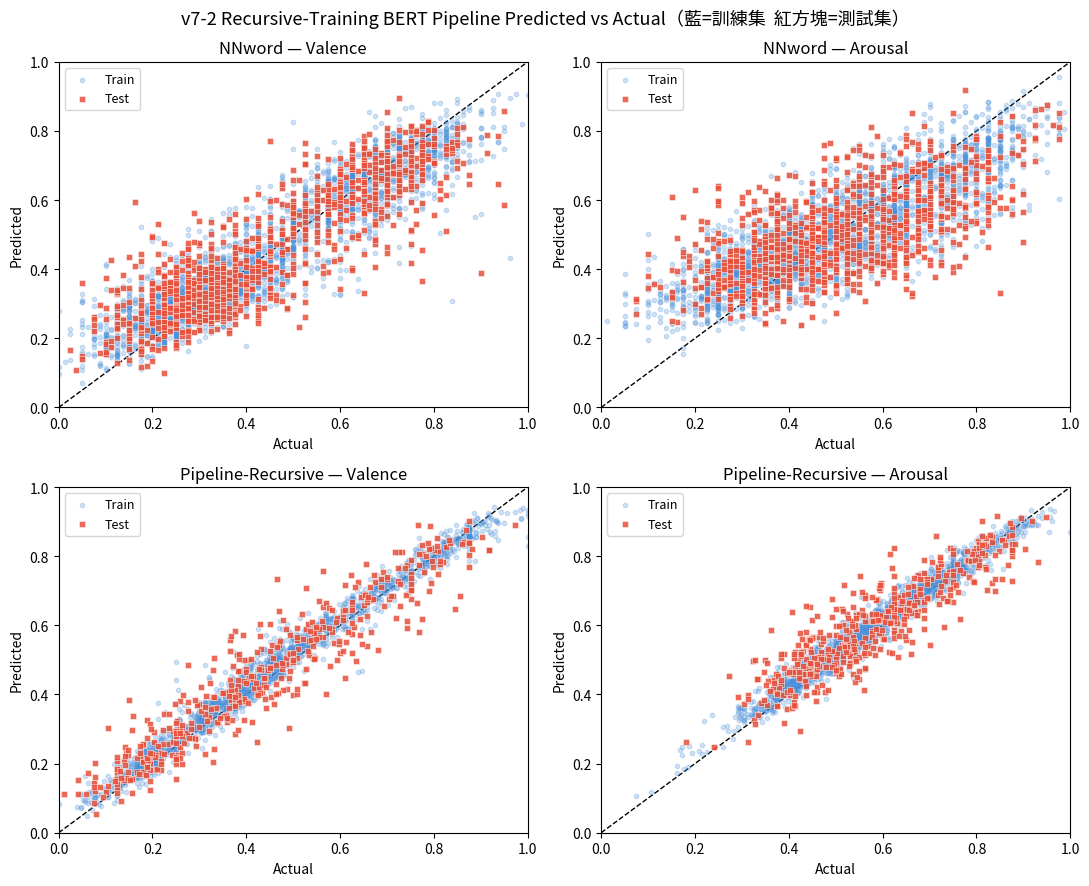

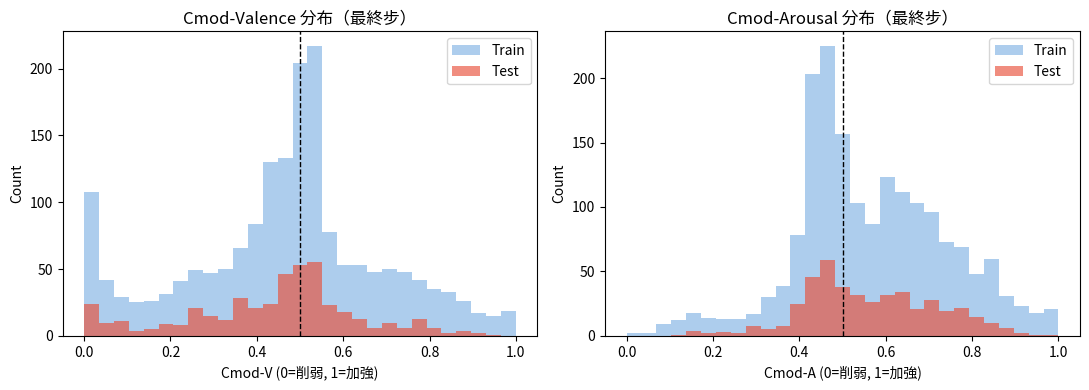

Test Cmod-V mean=0.438, std=0.200
Test Cmod-A mean=0.562, std=0.154


In [22]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle('v7-2 Recursive-Training BERT Pipeline Predicted vs Actual（藍=訓練集  紅方塊=測試集）', fontsize=13)
configs = [
    (axes[0,0], pv_trw, word_train_val, pv_tew, word_test_val, 'NNword — Valence',   '#4A90D9', '#E8503A'),
    (axes[0,1], pa_trw, word_train_aro, pa_tew, word_test_aro, 'NNword — Arousal',   '#4A90D9', '#E8503A'),
    (axes[1,0], pv_trm, phrase_train_val, pv_tem, phrase_test_val, 'Pipeline-Recursive — Valence', '#4A90D9', '#E8503A'),
    (axes[1,1], pa_trm, phrase_train_aro, pa_tem, phrase_test_aro, 'Pipeline-Recursive — Arousal', '#4A90D9', '#E8503A'),
]
for ax, ptr, gtr, pte, gte, title, c_tr, c_te in configs:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color=c_tr, label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color=c_te, marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0,1],[0,1],'k--', linewidth=1, zorder=1)
    ax.set_xlim(0,1); ax.set_ylim(0,1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()
# c_mod 雙維度視覺化（Valence shift / Arousal shift）
_, _, cmv_tr, cma_tr = batch_predict_phrase_recursive(train_chain_samples, return_shift=True)
_, _, cmv_te, cma_te = batch_predict_phrase_recursive(test_chain_samples, return_shift=True)
fig2, axes2 = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(0.0, 1.0, 30)
axes2[0].hist(cmv_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[0].hist(cmv_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[0].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[0].set_title('Cmod-Valence 分布（最終步）')
axes2[0].set_xlabel('Cmod-V (0=削弱, 1=加強)')
axes2[0].set_ylabel('Count')
axes2[0].legend()
axes2[1].hist(cma_tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
axes2[1].hist(cma_te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
axes2[1].axvline(0.5, color='k', linestyle='--', linewidth=1)
axes2[1].set_title('Cmod-Arousal 分布（最終步）')
axes2[1].set_xlabel('Cmod-A (0=削弱, 1=加強)')
axes2[1].set_ylabel('Count')
axes2[1].legend()
plt.tight_layout(); plt.show()
print(f'Test Cmod-V mean={cmv_te.mean():.3f}, std={cmv_te.std():.3f}')
print(f'Test Cmod-A mean={cma_te.mean():.3f}, std={cma_te.std():.3f}')

## [新增] NNword / NNmod 預測 VA 分布散佈圖（仿論文 Fig. 3 樣式）

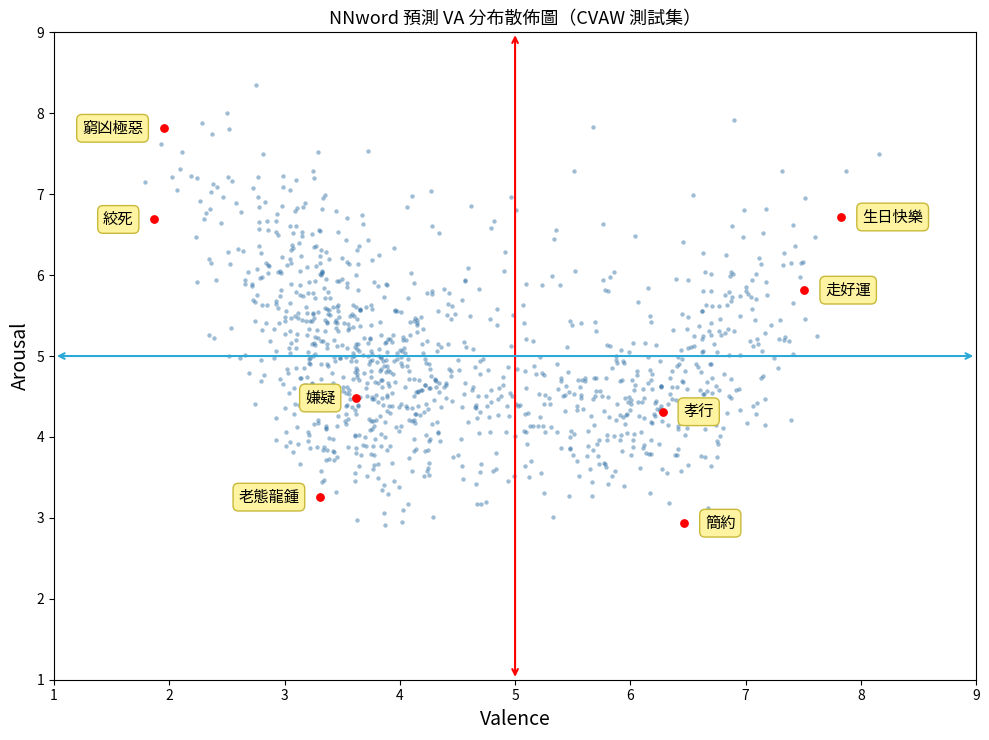

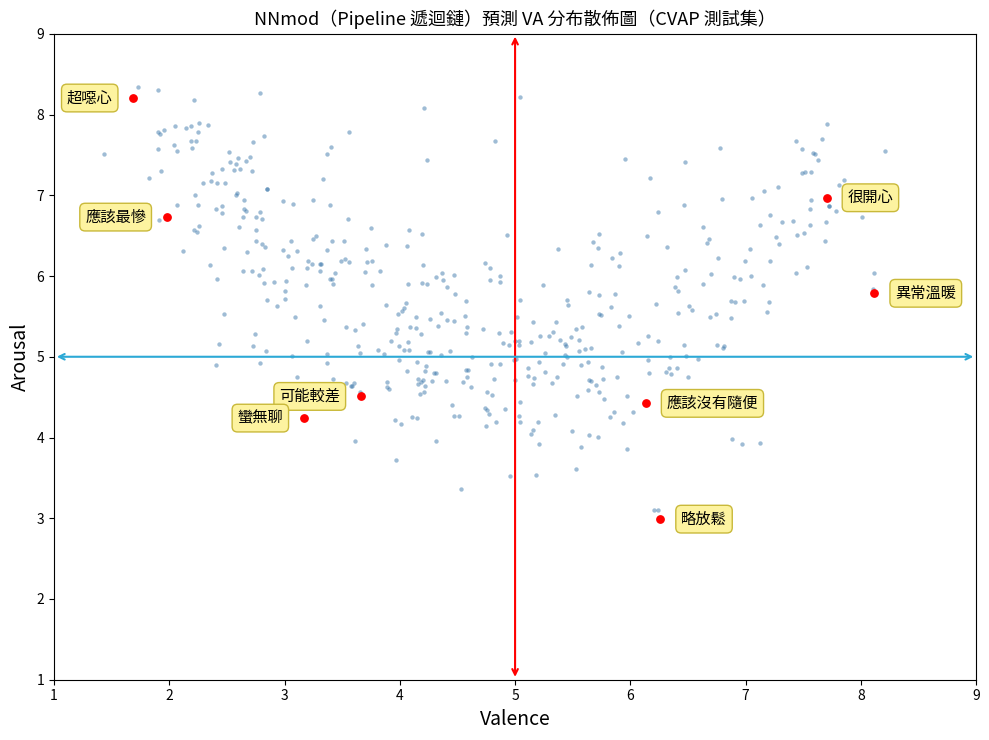

In [23]:
plot_va_scatter(pv_tew, pa_tew, cvaw_test['Word'].tolist(),
                'NNword 預測 VA 分布散佈圖（CVAW 測試集）', savepath='nnword_va_scatter.png')
plot_va_scatter(pv_tem, pa_tem, [s['full_phrase'] for s in test_chain_samples],
                'NNmod（Pipeline 遞迴鏈）預測 VA 分布散佈圖（CVAP 測試集）', savepath='nnmod_va_scatter.png')

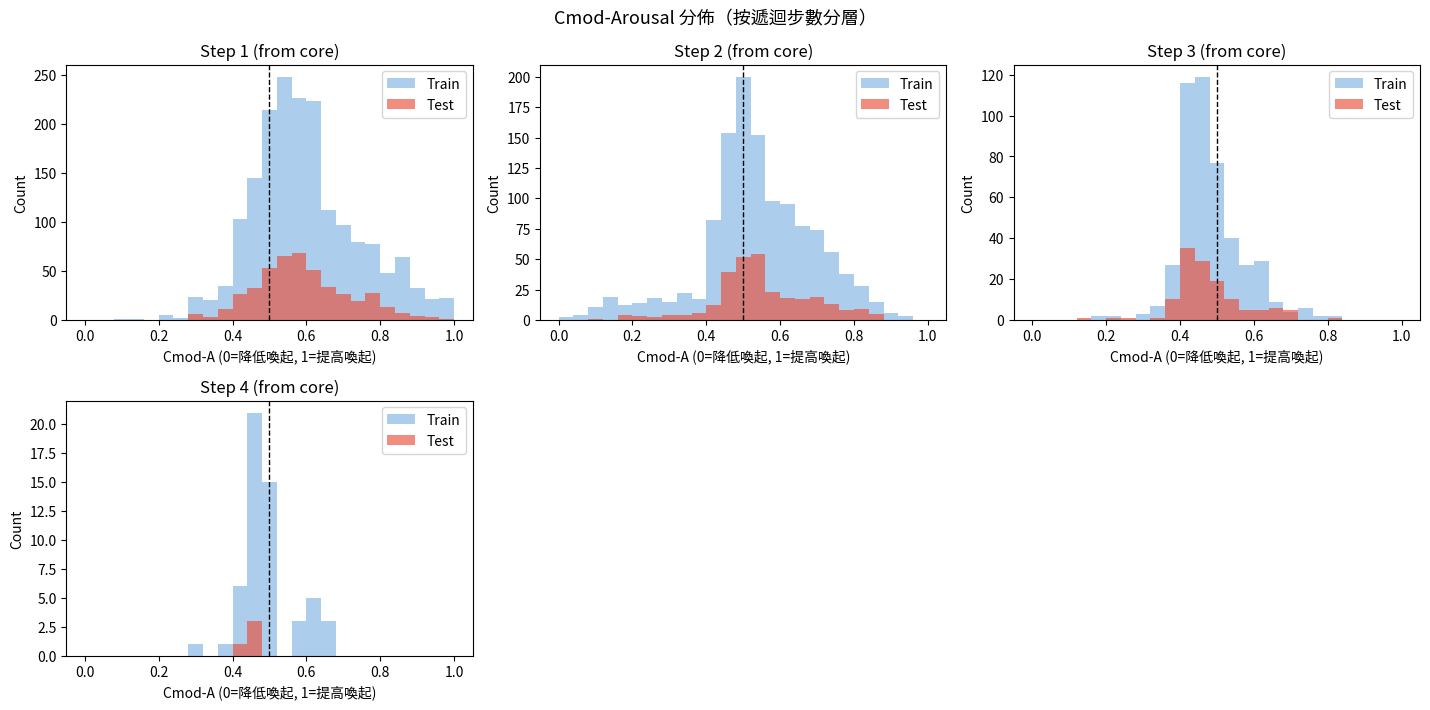

=== 每一步 Cmod-A 統計（Test）===
Step 1: mean=0.590, std=0.126, n=450
Step 2: mean=0.553, std=0.135, n=293
Step 3: mean=0.479, std=0.097, n=129
Step 4: mean=0.449, std=0.017, n=4


In [24]:
@torch.no_grad()
def collect_cmod_a_by_step(samples):
    model_word.eval()
    model_mod.eval()
    step_to_vals = {}
    for s in samples:
        core_t = torch.tensor(s['core_vec']).unsqueeze(0).to(device)
        cur_v, cur_a = model_word(core_t)
        for step_idx, ctx_np in enumerate(s['ctx_chain'], start=1):
            ctx_t = torch.tensor(ctx_np).unsqueeze(0).to(device)
            cur_v, cur_a, _, c_mod_a = model_mod(cur_v, cur_a, ctx_t)
            step_to_vals.setdefault(step_idx, []).append(c_mod_a.item())
    return {k: np.array(v, dtype=np.float32) for k, v in step_to_vals.items()}

train_a_by_step = collect_cmod_a_by_step(train_chain_samples)
test_a_by_step = collect_cmod_a_by_step(test_chain_samples)
all_steps = sorted(set(train_a_by_step.keys()) | set(test_a_by_step.keys()))
if not all_steps:
    raise ValueError('沒有可用的遞迴步數資料，請先確認 train_chain_samples / test_chain_samples。')
n_steps = len(all_steps)
n_cols = min(3, n_steps)
n_rows = int(np.ceil(n_steps / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.8 * n_cols, 3.6 * n_rows), squeeze=False)
bins = np.linspace(0.0, 1.0, 26)
for i, step in enumerate(all_steps):
    r = i // n_cols
    c = i % n_cols
    ax = axes[r, c]
    tr = train_a_by_step.get(step, np.array([], dtype=np.float32))
    te = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(tr) > 0:
        ax.hist(tr, bins=bins, alpha=0.45, color='#4A90D9', label='Train')
    if len(te) > 0:
        ax.hist(te, bins=bins, alpha=0.65, color='#E8503A', label='Test')
    ax.axvline(0.5, color='k', linestyle='--', linewidth=1)
    ax.set_title(f'Step {step} (from core)')
    ax.set_xlabel('Cmod-A (0=降低喚起, 1=提高喚起)')
    ax.set_ylabel('Count')
    ax.legend()
for j in range(n_steps, n_rows * n_cols):
    rr = j // n_cols
    cc = j % n_cols
    axes[rr, cc].axis('off')
fig.suptitle('Cmod-Arousal 分佈（按遞迴步數分層）', fontsize=13)
plt.tight_layout()
plt.show()
print('=== 每一步 Cmod-A 統計（Test）===')
for step in all_steps:
    vals = test_a_by_step.get(step, np.array([], dtype=np.float32))
    if len(vals) == 0:
        continue
    print(f'Step {step}: mean={vals.mean():.3f}, std={vals.std():.3f}, n={len(vals)}')

## 14. Stage 3（v8-UniCtx2）：統一語境的句子層級 NNsent

**這一版是 v8-UniCtx 的修改版，依四點修改意見：**

1. **NNword 前面加一層「微調層」**（Stage 1，見第 4、6 節）：BERT 向量 → `Dropout` → 殘差 adapter（`Linear→ReLU→Dropout→Linear`）→ NNword head，
   NNword 訓練加上 L1 / L2 與驗證集挑 epoch。BERT 本身仍然不動（向量預先算好），可訓練的是這一層。
2. **KNN 整個拿掉**：沒有鄰居特徵、沒有 `conf`、沒有 gate、沒有 `lex_nb`。NNsent 的每個 span 只剩 6 維 meta。
3. **NNsent 斷詞重寫**（14.2c）：改成 `jieba`（繁體詞典）先斷詞，再以「整個詞」比對 CVAW，不再用字元子字串比對。
   v8-UniCtx 的問題：`強調` 會被切出 `強`、`視病如親` 被切出 `親`（字元子字串命中）；OOV 候選還會收進 `真的`、`極了`、`這種`、`雖然` 這類功能詞。
4. **NNsent 的 L1 / L2 加強**：預設 L2 從 1e-4 → 1e-3、L1 從 1e-5 → 5e-5，另外加 dropout（對整句向量 0.3、隱藏層 0.2）與 patience 早停；
   並附一個選用的小型 sweep（`RUN_REG_SWEEP`），用**驗證集**挑 L1 / L2，不要用測試集挑。

**沒變的：** 統一路徑（每個 span 都走 `先驗 → BERT(span [SEP] 整句) → 同一個 adapter → 同一個遞迴 step`，沒有 `hit` 分支）、
Stage 2 NNmod、CVAS 的切分與評估、14.6 的 Leave-One-Out 排行榜。

```
每個 span: meta = [v0, a0, cmv, cma, hit, is_lex]
           先驗 (v0,a0)：NNword(核心詞)，有修飾詞再沿 NNmod 鏈走完
           ctx = BERT(span [SEP] 整句)         # max_length=128
           (v_adj, a_adj) = SpanContextAdapter(Dropout(ctx), meta)
遞迴：     (cur_v, cur_a) <- NNsent.step((cur_v, cur_a), [v_adj, a_adj, cmv, cma, hit, is_lex])
最後：     V → A 修正頭
```
`is_lex` = 這個 span 的核心詞在不在 CVAW（1/0）。它**不**區分「NNword 看過／沒看過」（CVAW 的訓練詞與測試詞都是 1），只是讓 NNsent 知道這個 VA 是來自詞典詞還是 OOV 詞。
`OOV_SPANS` 預設關閉（False）：沒有 KNN 之後，沒有可靠的標準挑 OOV 詞，要開的話只能用功能詞停用表，是實驗性質。

### 14.0 設定與開關

In [25]:
import re, os, copy, sys, subprocess, urllib.request

# ---- 斷詞 / span ----
OOV_SPANS   = False   # 是否把「不在 CVAW」的詞也當 span（實驗性質；用停用表過濾功能詞，沒有 KNN 之後沒有別的標準）
MAX_SPANS   = 8       # 一句最多取幾個 span
MOD_WINDOW  = 3       # 情感詞往前最多收幾個「相鄰的修飾詞 token」
SENT_MAXLEN = 128     # BERT(span [SEP] sentence) 的最大長度（v7 只有 16，會把整句截掉）

# ---- NNsent 訓練 / 正則化（比 v7-3c / v8-UniCtx 的 L2=1e-4, L1=1e-5 加強）----
SENT_L2        = 1e-3   # L2（Adam weight_decay）
SENT_L1        = 5e-5   # L1（手動加進 loss，只對 Linear 權重矩陣，不含 bias / LayerNorm）
SENT_DROP_CTX  = 0.3    # 對「整句 BERT 向量」做 dropout
SENT_DROP      = 0.2    # 隱藏層 dropout
LR_SENT        = 1e-3
N_EPOCHS_SENT  = 50
PATIENCE_SENT  = 15     # 驗證 loss 連續這麼多 epoch 沒進步就停
GRAD_ACCUM_SENT = 16
RUN_REG_SWEEP  = False  # True = 在 14.4b 用驗證集試一組 (L1, L2) 網格（要花一些時間）
SEED           = 42

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

try:
    import jieba
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'jieba'], check=False)
    import jieba

print(f'OOV_SPANS={OOV_SPANS}  MAX_SPANS={MAX_SPANS}  MOD_WINDOW={MOD_WINDOW}  SENT_MAXLEN={SENT_MAXLEN}')
print(f'NNsent 正則化: L2={SENT_L2}  L1={SENT_L1}  dropout(ctx/hidden)={SENT_DROP_CTX}/{SENT_DROP}  patience={PATIENCE_SENT}')

/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:44: SyntaxWarning: invalid escape sequence '\.'
  re_han_default = re.compile("([\u4E00-\u9FD5a-zA-Z0-9+#&\._%\-]+)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/__init__.py:46: SyntaxWarning: invalid escape sequence '\s'
  re_skip_default = re.compile("(\r\n|\s)", re.U)
/usr/local/lib/python3.13/dist-packages/jieba/finalseg/__init__.py:78: SyntaxWarning: invalid escape sequence '\.'
  re_skip = re.compile("([a-zA-Z0-9]+(?:\.\d+)?%?)")
/usr/local/lib/python3.13/dist-packages/jieba/_compat.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


OOV_SPANS=False  MAX_SPANS=8  MOD_WINDOW=3  SENT_MAXLEN=128
NNsent 正則化: L2=0.001  L1=5e-05  dropout(ctx/hidden)=0.3/0.2  patience=15


### 14.1 CVAS 前處理（正規化 + 切分，沿用 `normalize_va`，不重新定義）

In [26]:
cvas = normalize_va(cvas)
cvas_train_full, cvas_test = train_test_split(cvas, test_size=0.2, random_state=42)
# 再從訓練集切一份驗證集：完全不參與梯度更新，只用來監控 overfitting 與挑最佳 epoch；
# cvas_test 維持完全不動，只在全部訓練結束後看一次。
cvas_train, cvas_val = train_test_split(cvas_train_full, test_size=0.15, random_state=42)
print(f'CVAS 訓練:{len(cvas_train)}  驗證:{len(cvas_val)}  測試:{len(cvas_test)}')
print(cvas_train[['Text', 'valence', 'arousal']].head().to_string(index=False))

CVAS 訓練:1756  驗證:310  測試:517
              Text  valence  arousal
整個官僚機制和國民內鬥的齒輪咬合咬合 0.312500 0.625000
           王岐山器重明鏡 0.625000 0.312500
        偶爾在陰雨綿綿的夜晚 0.425000 0.281250
         如果我果斷獨自沉澱 0.416625 0.333375
       但情人海灘仍然美得驚人 0.875000 0.800000


### 14.2a 斷詞器：`jieba` + 繁體詞典，並把 CVAW 的詞加進詞典

- `jieba` 預設詞典是簡體，對繁體中文斷得不好（例如 `風景` 被斷成 `風`＋`景美`），所以改用 `dict.txt.big`（jieba 專案提供、對繁體比較友善）。
  第一次執行會從 GitHub 下載，下載失敗就退回預設詞典並提醒。
- 把 CVAW 裡 2 字以上的詞用 `jieba.add_word` 加進去，讓情感詞盡量被當成一個詞斷出來（`add_word` 預設不會把詞頻灌得過高，不會硬切壞其他詞）。

In [27]:
DICT_BIG = 'dict.txt.big'
DICT_URL = 'https://raw.githubusercontent.com/fxsjy/jieba/master/extra_dict/dict.txt.big'
if not os.path.exists(DICT_BIG):
    try:
        urllib.request.urlretrieve(DICT_URL, DICT_BIG)
        print('已下載繁體詞典 dict.txt.big')
    except Exception as e:
        print(f'⚠ 下載繁體詞典失敗（{e}），改用 jieba 預設詞典，斷詞品質會比較差')
if os.path.exists(DICT_BIG):
    jieba.set_dictionary(DICT_BIG)
jieba.initialize()
for _w in cvaw_word_set:
    if len(_w) >= 2:
        jieba.add_word(_w)
print(f'jieba 準備完成（CVAW 詞 {len(cvaw_word_set)} 個）')

Building prefix dict from /content/dict.txt.big ...
DEBUG:jieba:Building prefix dict from /content/dict.txt.big ...


已下載繁體詞典 dict.txt.big


Dumping model to file cache /tmp/jieba.u501edca284da514cb68b53a20324f4e3.cache
DEBUG:jieba:Dumping model to file cache /tmp/jieba.u501edca284da514cb68b53a20324f4e3.cache
Loading model cost 1.272 seconds.
DEBUG:jieba:Loading model cost 1.272 seconds.
Prefix dict has been built successfully.
DEBUG:jieba:Prefix dict has been built successfully.


jieba 準備完成（CVAW 詞 5512 個）


### 14.2b NNword 的向量快取與預測（沿用 Stage 1 的 `model_word`，全程凍結）

In [28]:
def prefetch_core_vecs(words, batch_size=64):
    """把還沒快取的詞一次批次算好 BERT 單詞向量，放進 core_cache（比逐個算快很多）。"""
    missing = [w for w in dict.fromkeys(words) if w not in core_cache]
    if not missing:
        return
    vecs = get_bert_vecs_batch(missing, batch_size=batch_size)
    for w, v in zip(missing, vecs):
        core_cache[w] = v


_nnword_cache = {}


@torch.no_grad()
def nnword_va(word):
    """NNword 對單一詞的 VA 估計（凍結、有快取）。"""
    if word not in _nnword_cache:
        model_word.eval()
        vec = torch.tensor(get_core_vec_cached(word)).unsqueeze(0).to(device)
        v, a = model_word(vec)
        _nnword_cache[word] = (v.item(), a.item())
    return _nnword_cache[word]

### 14.2c 句子 → span 切割（所有 span 同一條路）

流程：`jieba` 斷詞 → 逐個 token 看是不是 CVAW 的詞（**整個 token 比對**，不是字元子字串）→ 往前收緊鄰的修飾詞 token（`非常`、`不`、`完全`……，不跨標點）。

- token 本身就是 CVAW 詞 → 核心詞。
- token 是「修飾詞＋CVAW 詞」被 jieba 連在一起（例如 `不開心`）→ 用 `split_phrase` 拆開，且要求修飾詞每一個都是 `MODIFIER_LEXICON` 認得的否定／程度詞。
- 沒有任何 span → 把整句當一個 span（fallback，樣本極少）。
- `OOV_SPANS=True`（預設關閉）：不在 CVAW、長度≥2、純中文、不是修飾詞、不在功能詞停用表的 token 也收進來（`kind='oov'`）。

一個 span 的「meta」固定 6 維，所有 span 一樣：`[v0, a0, cmv, cma, hit, is_lex]`。
`v0/a0` = NNword（有修飾詞再接 NNmod 鏈）算出的 VA；`hit` = 有沒有修飾詞（**只是特徵**）；`is_lex` = 核心詞在不在 CVAW。

In [29]:
_MODIFIER_SET = set(MODIFIER_LEXICON)
_CJK_ONLY = re.compile(r'^[一-鿿]+$')

# OOV 模式才會用到：常見功能詞（代名詞、連接詞、助詞、指示詞、常見副詞），不當成情感 span
STOPWORDS = {
    '這次', '這種', '這個', '那個', '這些', '那些', '這樣', '那樣', '這裡', '那裡', '我們', '你們', '他們', '她們', '自己', '大家',
    '什麼', '怎麼', '為什麼', '因為', '所以', '雖然', '但是', '可是', '不過', '如果', '假如', '然後', '而且', '或者', '還是', '以及',
    '已經', '正在', '就是', '只是', '其實', '真的', '可能', '應該', '一個', '一些', '一樣', '一直', '一起', '一定', '甚至', '終於',
    '還算', '覺得', '知道', '看到', '時候', '之後', '之前', '現在', '今天', '昨天', '明天', '極了', '得很', '起來', '下去', '出來',
}


def _span_from_token(tok):
    """token → (modifier_text, chain, core)，不是 CVAW 詞也不是「修飾詞+CVAW詞」就回傳 None。"""
    if tok in cvaw_word_set:
        return None, [], tok
    if len(tok) >= 2:
        m, c, ch = split_phrase(tok, cvaw_word_set)
        if c is not None and m and ch and all(t in _MODIFIER_SET for t in ch):
            return m, ch, c
    return None


def extract_spans(sentence, max_spans=MAX_SPANS):
    sentence = str(sentence).strip()
    toks = jieba.lcut(sentence)
    spans, covered, seen_texts = [], set(), set()

    for idx, tok in enumerate(toks):
        r = _span_from_token(tok)
        if r is None:
            continue
        mod_in_tok, chain_in_tok, core = r
        pre, j = [], idx - 1                       # 往前收緊鄰、且是修飾詞的 token（遇到標點或別的詞就停）
        while j >= 0 and len(pre) < MOD_WINDOW and toks[j] in _MODIFIER_SET:
            pre.insert(0, toks[j]); j -= 1
        mod_text = ''.join(pre) + (mod_in_tok or '')
        chain = []
        if mod_text:
            chain = split_modifier_chain(mod_text)
            if not (chain and all(t in _MODIFIER_SET for t in chain)):
                mod_text, chain, pre = '', [], []  # 不是合法的修飾詞鏈就當作沒有修飾詞
        text = mod_text + core
        if text in seen_texts:
            continue
        seen_texts.add(text)
        covered.update(range(idx - len(pre), idx + 1))
        spans.append(dict(order=idx, text=text, mod=mod_text or None, core=core, chain=chain, kind='lex'))

    spans = spans[:max_spans]

    if OOV_SPANS and len(spans) < max_spans:
        for idx, tok in enumerate(toks):
            if len(spans) >= max_spans:
                break
            if (idx not in covered and len(tok) >= 2 and _CJK_ONLY.match(tok) and tok not in cvaw_word_set
                    and tok not in _MODIFIER_SET and tok not in STOPWORDS and tok not in seen_texts):
                seen_texts.add(tok)
                spans.append(dict(order=idx, text=tok, mod=None, core=tok, chain=[], kind='oov'))

    if not spans:
        spans = [dict(order=0, text=sentence, mod=None, core=None, chain=[], kind='fallback')]
    spans.sort(key=lambda x: x['order'])
    return spans


@torch.no_grad()
def get_span_sentence_vecs(span_texts, sentence, max_length=SENT_MAXLEN):
    """BERT(span [SEP] 整句)：跟 NNmod 的 BERT(modifier [SEP] core) 同一個手法，
    只是第二段從「片語」換成「整句」。max_length=128，不再像 v7 只看前 14 個字。"""
    bert_model.eval()
    enc = tokenizer(list(span_texts), [sentence] * len(span_texts), return_tensors='pt',
                    padding=True, truncation='longest_first', max_length=max_length).to(device)
    out = bert_model(**enc)
    return out.last_hidden_state[:, 0, :].cpu().numpy().astype(np.float32)


META_NAMES = ['v0', 'a0', 'cmv', 'cma', 'hit', 'is_lex']
META_DIM = len(META_NAMES)


@torch.no_grad()
def build_span_meta(sp):
    """對一個 span 算 meta（所有 span 同一個函式，沒有 kind 分支）。
    先驗 (v0,a0)：沒有修飾詞 → NNword(核心詞)；有修飾詞 → 再沿 NNmod 鏈走完。"""
    model_word.eval(); model_mod.eval()
    core, chain = sp['core'], sp['chain']
    word = core if core is not None else sp['text']          # fallback：整句當一個「詞」
    v0, a0 = nnword_va(word)
    cmv, cma, hit = 0.5, 0.5, 0.0
    if chain:
        ct = torch.tensor(get_core_vec_cached(word)).unsqueeze(0).to(device)
        cv, ca = model_word(ct)
        cm_v = torch.tensor([[0.5]], device=device); cm_a = torch.tensor([[0.5]], device=device)
        cur_label = word
        for m in reversed(chain):
            ctx_t = torch.tensor(get_pair_vec_cached(str(m), cur_label)).unsqueeze(0).to(device)
            cv, ca, cm_v, cm_a = model_mod(cv, ca, ctx_t)
            cur_label = str(m) + cur_label
        v0, a0, cmv, cma, hit = cv.item(), ca.item(), cm_v.item(), cm_a.item(), 1.0
    is_lex = 1.0 if (core is not None and core in cvaw_word_set) else 0.0
    return [v0, a0, cmv, cma, hit, is_lex]


pool_set = set(cvaw_train['Word'].astype(str))        # NNword 訓練時看過的詞


def _seen_state(sp):
    if sp['core'] is None:
        return 'fallback'
    if sp['core'] in pool_set:
        return 'seen'            # NNword 訓練時看過
    if sp['core'] in cvaw_word_set:
        return 'unseen_lex'      # 在 CVAW，但 NNword 沒看過（驗證詞或測試詞）
    return 'oov'                 # 完全不在 CVAW


def make_sample(sentence, spans):
    ctx = get_span_sentence_vecs([sp['text'] for sp in spans], sentence)
    meta = np.array([build_span_meta(sp) for sp in spans], dtype=np.float32)
    infos = [{'span_text': sp['text'], 'modifier': sp['mod'], 'core_word': sp['core'],
              'hit': int(meta[i, 4]), 'kind': sp['kind'], 'seen_state': _seen_state(sp)}
             for i, sp in enumerate(spans)]
    return {'ctx': ctx, 'meta': meta, 'span_infos': infos, 'sentence': sentence}


def build_unified_sample(sentence):
    sentence = str(sentence).strip()
    spans = extract_spans(sentence)
    prefetch_core_vecs([sp['core'] if sp['core'] is not None else sp['text'] for sp in spans])
    return make_sample(sentence, spans)


def build_cvas_samples(df, tag=''):
    sents = [str(t).strip() for t in df['Text']]
    all_spans = [extract_spans(s) for s in sents]
    prefetch_core_vecs([sp['core'] if sp['core'] is not None else sp['text'] for spans in all_spans for sp in spans])
    samples, kinds, states = [], {}, {}
    for n, ((_, row), s, spans) in enumerate(zip(df.iterrows(), sents, all_spans), start=1):
        smp = make_sample(s, spans)
        smp['valence'], smp['arousal'] = float(row['valence']), float(row['arousal'])
        samples.append(smp)
        for info in smp['span_infos']:
            kinds[info['kind']] = kinds.get(info['kind'], 0) + 1
            states[info['seen_state']] = states.get(info['seen_state'], 0) + 1
        if n % 500 == 0:
            print(f'  {tag} {n}/{len(df)}')
    tot = max(sum(kinds.values()), 1)
    print(f'  [{tag}] 平均每句 {tot / max(len(samples), 1):.2f} 個 span')
    print(f'  [{tag}] span 種類：' + '  '.join(f'{k}={v}({v / tot * 100:.1f}%)' for k, v in sorted(kinds.items())))
    print(f'  [{tag}] 詞的「看過」狀態：' + '  '.join(f'{k}={v}({v / tot * 100:.1f}%)' for k, v in sorted(states.items())))
    return samples


print('extract_spans / build_unified_sample 定義完成')

extract_spans / build_unified_sample 定義完成


### 14.2d 斷詞檢查：看 `jieba` 斷出什麼、哪些詞被收成 span

v8-UniCtx 的 demo 裡出現過 `強`（來自「強調」）、`親`（來自「視病如親」）、`真的`、`極了`、`這種`、`雖然` 這類奇怪的 span，這裡可以直接看新的斷詞結果。
想測自己的句子就改下面的 list。

In [30]:
_demo_sents = [
    '這次旅行真的非常開心，風景美極了！',
    '主治醫師強調血液透析，家屬卻遲遲無法達到共識。',
    '視病如親，讓我十分的動容。',
    '雖然考試沒過，但心情還算平靜。',
    '非常憤怒，完全無法接受這種行為！',
]
for _s in _demo_sents:
    print(f'句子：{_s}')
    print('  jieba：', ' / '.join(jieba.lcut(_s)))
    print('  span ：', [(sp["text"], sp["kind"]) for sp in extract_spans(_s)])

句子：這次旅行真的非常開心，風景美極了！
  jieba： 這次 / 旅行 / 真的 / 非常 / 開心 / ， / 風景 / 美極了 / ！
  span ： [('非常開心', 'lex')]
句子：主治醫師強調血液透析，家屬卻遲遲無法達到共識。
  jieba： 主治醫師 / 強調 / 血液 / 透析 / ， / 家屬 / 卻 / 遲遲 / 無法 / 達到 / 共識 / 。
  span ： [('無法', 'lex'), ('達到', 'lex')]
句子：視病如親，讓我十分的動容。
  jieba： 視病 / 如親 / ， / 讓 / 我 / 十分 / 的 / 動容 / 。
  span ： [('視病如親，讓我十分的動容。', 'fallback')]
句子：雖然考試沒過，但心情還算平靜。
  jieba： 雖然 / 考試 / 沒 / 過 / ， / 但 / 心情 / 還 / 算 / 平靜 / 。
  span ： [('心情', 'lex'), ('平靜', 'lex')]
句子：非常憤怒，完全無法接受這種行為！
  jieba： 非常 / 憤怒 / ， / 完全 / 無法 / 接受 / 這種 / 行為 / ！
  span ： [('非常憤怒', 'lex'), ('無法', 'lex'), ('接受', 'lex')]


### 14.3 NNsent（v8-UniCtx2）：一個 adapter + 一個遞迴 step，所有 span 同一條路

- `SpanContextAdapter` 對每個 span 獨立計算：`Dropout(整句 BERT 向量)` ⊕ `meta`（含先驗 VA），輸出 logit 空間的殘差平移（`tanh*0.5` 限幅）。
  剛開始訓練 bias=0、delta≈0，等於先退化成 NNword／NNmod 的先驗。
- `NNsent.forward()` 沒有任何依 `hit`、`kind`、`ctx is None` 的分支。
- 沒有 KNN：沒有 `conf`、沒有 gate。

In [31]:
class SpanContextAdapter(nn.Module):
    def __init__(self, bert_dim=768, hidden=128, p_ctx=0.3, p=0.2):
        super().__init__()
        self.ctx_drop = nn.Dropout(p_ctx)                # 對整句向量做 dropout（768 維、最容易背訓練句子）
        in_dim = bert_dim + META_DIM                     # ctx ⊕ meta
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, hidden // 2)
        self.fc3 = nn.Linear(hidden // 2, 2)
        self.ln1 = nn.LayerNorm(hidden)
        self.ln2 = nn.LayerNorm(hidden // 2)
        self.drop = nn.Dropout(p)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)

    def forward(self, ctx, meta):
        x = torch.cat([self.ctx_drop(ctx), meta], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        v0 = meta[:, 0:1].clamp(0.01, 0.99)
        a0 = meta[:, 1:2].clamp(0.01, 0.99)
        out_v = torch.sigmoid(torch.logit(v0) + delta[:, 0:1] * 3)
        out_a = torch.sigmoid(torch.logit(a0) + delta[:, 1:2] * 3)
        return out_v, out_a


class NNsent(nn.Module):
    def __init__(self, hidden=64, bert_dim=BERT_DIM, p_ctx=0.3, p=0.2):
        super().__init__()
        self.adapter = SpanContextAdapter(bert_dim=bert_dim, hidden=128, p_ctx=p_ctx, p=p)
        feat_dim = 2 + 6
        self.fc1 = nn.Linear(feat_dim, hidden * 2)
        self.fc2 = nn.Linear(hidden * 2, hidden)
        self.fc3 = nn.Linear(hidden, 2)
        self.ln1 = nn.LayerNorm(hidden * 2)
        self.ln2 = nn.LayerNorm(hidden)
        self.drop = nn.Dropout(p)
        for layer in [self.fc1, self.fc2, self.fc3]:
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
        # 最終 Arousal 修正頭（V 幫助 A），沿用 v7-3
        self.aro_fc = nn.Linear(2, hidden)
        self.aro_ln = nn.LayerNorm(hidden)
        self.aro_out = nn.Linear(hidden, 1)
        nn.init.xavier_uniform_(self.aro_fc.weight); nn.init.zeros_(self.aro_fc.bias)
        nn.init.xavier_uniform_(self.aro_out.weight); nn.init.zeros_(self.aro_out.bias)

    def step(self, cur_v, cur_a, span_feat):
        x = torch.cat([cur_v, cur_a, span_feat], dim=1)
        h = torch.relu(self.ln1(self.fc1(x)))
        h = self.drop(h)
        h = torch.relu(self.ln2(self.fc2(h)))
        delta = torch.tanh(self.fc3(h)) * 0.5
        new_v = torch.sigmoid(torch.logit(cur_v.clamp(0.01, 0.99)) + delta[:, 0:1] * 3)
        new_a = torch.sigmoid(torch.logit(cur_a.clamp(0.01, 0.99)) + delta[:, 1:2] * 3)
        return new_v, new_a, delta[:, 0:1] + 0.5, delta[:, 1:2] + 0.5

    def forward(self, ctx, meta):
        """
        ctx : (S, bert_dim)  每個 span 的 BERT(span [SEP] 整句) 向量
        meta: (S, META_DIM)  每個 span 的 meta（見 META_NAMES）
        S = 這句話實際的 span 數（依句中出現順序），單一句子、batch=1。
        回傳：final_v, final_a, steps（每一步的 (c_v, c_a)，可解釋性用）
        """
        dev = next(self.parameters()).device
        ctx_t = torch.as_tensor(ctx, dtype=torch.float32, device=dev)
        meta_t = torch.as_tensor(meta, dtype=torch.float32, device=dev)
        sv, sa = self.adapter(ctx_t, meta_t)                           # 所有 span 一次算完、同一條路
        feats = torch.cat([sv, sa, meta_t[:, 2:6]], dim=1)             # [v_adj, a_adj, cmv, cma, hit, is_lex]

        cur_v = torch.full((1, 1), 0.5, device=dev)
        cur_a = torch.full((1, 1), 0.5, device=dev)
        steps = []
        for i in range(feats.shape[0]):                                # 遞迴：依出現順序逐 span 套用
            cur_v, cur_a, c_v, c_a = self.step(cur_v, cur_a, feats[i:i + 1])
            steps.append((c_v.detach(), c_a.detach()))

        h = torch.relu(self.aro_ln(self.aro_fc(torch.cat([cur_v.detach(), cur_a], dim=1))))
        aro_delta = torch.tanh(self.aro_out(h)) * 0.5
        cur_a = torch.sigmoid(torch.logit(cur_a.clamp(0.01, 0.99)) + aro_delta * 3)
        return cur_v, cur_a, steps


print('NNsent（Stage 3，v8-UniCtx2：統一語境、無 KNN、加強正則化）定義完成')

NNsent（Stage 3，v8-UniCtx2：統一語境、無 KNN、加強正則化）定義完成


### 14.4 建立 CVAS 樣本

In [32]:
print('計算 CVAS 訓練集 span...')
cvas_train_samples = build_cvas_samples(cvas_train, '訓練')
print('計算 CVAS 驗證集 span...')
cvas_val_samples = build_cvas_samples(cvas_val, '驗證')
print('計算 CVAS 測試集 span...')
cvas_test_samples = build_cvas_samples(cvas_test, '測試')

cvas_train_val = np.array([s['valence'] for s in cvas_train_samples], dtype=np.float32)
cvas_train_aro = np.array([s['arousal'] for s in cvas_train_samples], dtype=np.float32)
cvas_val_val = np.array([s['valence'] for s in cvas_val_samples], dtype=np.float32)
cvas_val_aro = np.array([s['arousal'] for s in cvas_val_samples], dtype=np.float32)
cvas_test_val = np.array([s['valence'] for s in cvas_test_samples], dtype=np.float32)
cvas_test_aro = np.array([s['arousal'] for s in cvas_test_samples], dtype=np.float32)
print(f'CVAS 樣本: 訓練={len(cvas_train_samples)}  驗證={len(cvas_val_samples)}  測試={len(cvas_test_samples)}')

計算 CVAS 訓練集 span...
  訓練 500/1756
  訓練 1000/1756
  訓練 1500/1756
  [訓練] 平均每句 1.26 個 span
  [訓練] span 種類：fallback=178(8.0%)  lex=2042(92.0%)
  [訓練] 詞的「看過」狀態：fallback=178(8.0%)  seen=1391(62.7%)  unseen_lex=651(29.3%)
計算 CVAS 驗證集 span...
  [驗證] 平均每句 1.23 個 span
  [驗證] span 種類：fallback=27(7.1%)  lex=353(92.9%)
  [驗證] 詞的「看過」狀態：fallback=27(7.1%)  seen=239(62.9%)  unseen_lex=114(30.0%)
計算 CVAS 測試集 span...
  測試 500/517
  [測試] 平均每句 1.24 個 span
  [測試] span 種類：fallback=52(8.1%)  lex=590(91.9%)
  [測試] 詞的「看過」狀態：fallback=52(8.1%)  seen=411(64.0%)  unseen_lex=179(27.9%)
CVAS 樣本: 訓練=1756  驗證=310  測試=517


In [33]:
# 訊號天花板檢查（只看 CVAW 內詞的原始標註平均 vs 句子真實 VA；不影響下面的訓練）
cvaw_va_lookup = dict(zip(cvaw['Word'].astype(str), zip(cvaw['valence'], cvaw['arousal'])))
_pred_v, _pred_a, _true_v, _true_a, _n_no_match = [], [], [], [], 0
for _s in cvas_train_samples:
    _vs = [cvaw_va_lookup[i['core_word']] for i in _s['span_infos'] if i['core_word'] in cvaw_va_lookup]
    if not _vs:
        _n_no_match += 1
        continue
    _pred_v.append(float(np.mean([x[0] for x in _vs]))); _pred_a.append(float(np.mean([x[1] for x in _vs])))
    _true_v.append(_s['valence']); _true_a.append(_s['arousal'])
print(f'[診斷] 有對到至少一個 CVAW 詞的句子: {len(_pred_v)}/{len(cvas_train_samples)}  (完全沒對到: {_n_no_match})')
print(f'[診斷] Valence: 詞彙平均 vs 真實句子VA  Pearson r = {pearsonr(_pred_v, _true_v)[0]:.4f}')
print(f'[診斷] Arousal: 詞彙平均 vs 真實句子VA  Pearson r = {pearsonr(_pred_a, _true_a)[0]:.4f}')

[診斷] 有對到至少一個 CVAW 詞的句子: 1578/1756  (完全沒對到: 178)
[診斷] Valence: 詞彙平均 vs 真實句子VA  Pearson r = 0.5869
[診斷] Arousal: 詞彙平均 vs 真實句子VA  Pearson r = 0.2784


### 14.4a 訓練 NNsent（NNword、NNmod 全程凍結；L1 / L2 / dropout 加強，patience 早停）

`train_nnsent` 把整個訓練流程包成函式：給它 L1、L2、dropout，回傳驗證 loss 最低那個 epoch 的模型與曲線。
主訓練用 14.0 的預設值；14.4b 的 sweep 也是呼叫同一個函式，所以兩邊的訓練方式一致。

=== Stage 3：訓練 NNsent（v8-UniCtx2）===
    L2=0.001   L1=5e-05   dropout(ctx/hidden)=0.3/0.2   SEED=42
Epoch  10/50 | Train Loss: 0.020819 | Val Loss: 0.021016
Epoch  20/50 | Train Loss: 0.019579 | Val Loss: 0.022678
Epoch  30/50 | Train Loss: 0.018255 | Val Loss: 0.020855
Epoch  40/50 | Train Loss: 0.016712 | Val Loss: 0.019742
Epoch  50/50 | Train Loss: 0.016526 | Val Loss: 0.019850

改用驗證損失最低的權重（第 42 epoch，Val Loss=0.019533）


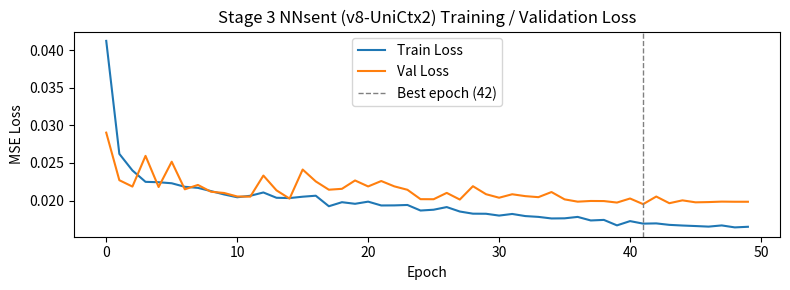

Stage 3 完成（NNword / NNmod 權重全程未被更新）


In [34]:
def l1_penalty(model):
    l1 = 0.0
    for p in model.parameters():
        if p.dim() >= 2:                  # 只對 Linear 權重矩陣；不含 bias / LayerNorm
            l1 = l1 + p.abs().sum()
    return l1


@torch.no_grad()
def eval_loss_sent(model, samples):
    """平均 MSE（純預測誤差，不含 L1/L2），拿來監控驗證集。"""
    model.eval()
    if not samples:
        return float('nan')
    total = 0.0
    for s in samples:
        y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
        y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
        pv, pa, _ = model(s['ctx'], s['meta'])
        total += (0.5 * ((pv - y_v) ** 2 + (pa - y_a) ** 2).mean()).item()
    return total / len(samples)


def train_nnsent(train_samples, val_samples, l1=SENT_L1, l2=SENT_L2, p_ctx=SENT_DROP_CTX, p_hid=SENT_DROP,
                 epochs=N_EPOCHS_SENT, patience=PATIENCE_SENT, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    rng = np.random.RandomState(seed)
    model = NNsent(hidden=64, p_ctx=p_ctx, p=p_hid).to(device)
    opt = optim.Adam(model.parameters(), lr=LR_SENT, weight_decay=l2)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
    losses_tr, losses_va = [], []
    best_val, best_epoch, best_state, bad = float('inf'), 0, None, 0

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        idxs = rng.permutation(len(train_samples))
        opt.zero_grad()
        for step_i, si in enumerate(idxs, start=1):
            s = train_samples[si]
            y_v = torch.tensor([[s['valence']]], dtype=torch.float32, device=device)
            y_a = torch.tensor([[s['arousal']]], dtype=torch.float32, device=device)
            pv, pa, _ = model(s['ctx'], s['meta'])
            loss_mse = 0.5 * ((pv - y_v) ** 2 + (pa - y_a) ** 2).mean()
            loss = loss_mse + l1 * l1_penalty(model) if l1 > 0 else loss_mse
            (loss / GRAD_ACCUM_SENT).backward()
            epoch_loss += loss_mse.item()
            if (step_i % GRAD_ACCUM_SENT == 0) or (step_i == len(idxs)):
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                opt.step()
                opt.zero_grad()
        sch.step()
        losses_tr.append(epoch_loss / len(idxs))
        val_loss = eval_loss_sent(model, val_samples)
        losses_va.append(val_loss)
        if val_loss < best_val - 1e-6:
            best_val, best_epoch, best_state, bad = val_loss, epoch + 1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if verbose and (epoch + 1) % 10 == 0:
            print(f'Epoch {epoch + 1:3d}/{epochs} | Train Loss: {losses_tr[-1]:.6f} | Val Loss: {val_loss:.6f}')
        if bad >= patience:
            if verbose:
                print(f'驗證 loss 連續 {patience} 個 epoch 沒進步，提早停止（epoch {epoch + 1}）')
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, {'train': losses_tr, 'val': losses_va, 'best_val': best_val, 'best_epoch': best_epoch}


print('=== Stage 3：訓練 NNsent（v8-UniCtx2）===')
print(f'    L2={SENT_L2}   L1={SENT_L1}   dropout(ctx/hidden)={SENT_DROP_CTX}/{SENT_DROP}   SEED={SEED}')
model_sent, hist_sent = train_nnsent(cvas_train_samples, cvas_val_samples)
best_epoch, best_val = hist_sent['best_epoch'], hist_sent['best_val']
losses_s, losses_s_val = hist_sent['train'], hist_sent['val']
print(f'\n改用驗證損失最低的權重（第 {best_epoch} epoch，Val Loss={best_val:.6f}）')

plt.figure(figsize=(8, 3))
plt.plot(losses_s, label='Train Loss')
plt.plot(losses_s_val, label='Val Loss')
plt.axvline(best_epoch - 1, color='gray', linestyle='--', linewidth=1, label=f'Best epoch ({best_epoch})')
plt.title('Stage 3 NNsent (v8-UniCtx2) Training / Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('MSE Loss')
plt.legend()
plt.tight_layout(); plt.show()
print('Stage 3 完成（NNword / NNmod 權重全程未被更新）')

### 14.4b（選用）用驗證集挑 L1 / L2

`RUN_REG_SWEEP=True` 才會跑。每組設定訓練一個縮短版（25 epoch、patience 8），只看**驗證集**的 loss 與 Pearson r，
挑到合適的值之後回到 14.0 改 `SENT_L1` / `SENT_L2`，再重跑 14.4a。**不要用測試集挑參數。**

In [35]:
@torch.no_grad()
def predict_samples(model, samples):
    model.eval()
    pv_, pa_ = [], []
    for s in samples:
        pv, pa, _ = model(s['ctx'], s['meta'])
        pv_.append(pv.item()); pa_.append(pa.item())
    return np.array(pv_, dtype=np.float32), np.array(pa_, dtype=np.float32)


if RUN_REG_SWEEP:
    rows_sweep = []
    for _l2 in [1e-4, 1e-3, 1e-2]:
        for _l1 in [0.0, 1e-5, 1e-4]:
            _m, _h = train_nnsent(cvas_train_samples, cvas_val_samples, l1=_l1, l2=_l2,
                                  epochs=25, patience=8, verbose=False)
            _pv, _pa = predict_samples(_m, cvas_val_samples)
            rows_sweep.append({'L2': _l2, 'L1': _l1, 'best_epoch': _h['best_epoch'], 'val_loss': _h['best_val'],
                               'val_r_V': pearsonr(_pv, cvas_val_val)[0], 'val_r_A': pearsonr(_pa, cvas_val_aro)[0]})
            print(f'  L2={_l2:g} L1={_l1:g} → val_loss={_h["best_val"]:.5f}  r_V={rows_sweep[-1]["val_r_V"]:.4f}  r_A={rows_sweep[-1]["val_r_A"]:.4f}')
    sweep_df = pd.DataFrame(rows_sweep).sort_values('val_loss')
    print('\n依驗證 loss 排序（越小越好）：')
    print(sweep_df.round(5).to_string(index=False))
else:
    print('RUN_REG_SWEEP=False，略過 sweep（要用的話把 14.0 的 RUN_REG_SWEEP 改成 True 再重跑）')

RUN_REG_SWEEP=False，略過 sweep（要用的話把 14.0 的 RUN_REG_SWEEP 改成 True 再重跑）


### 14.5 三階段完整評估（NNword / Pipeline / NNsent）＋ 與 v7-3c、v8-UniCtx 對照

In [36]:
pv_str, pa_str = predict_samples(model_sent, cvas_train_samples)
pv_sva, pa_sva = predict_samples(model_sent, cvas_val_samples)
pv_ste, pa_ste = predict_samples(model_sent, cvas_test_samples)

print('=' * 75)
print('【Stage 3：CVAS 句子層級評估（v8-UniCtx2）】')
print('=' * 75)
print('\n[NNsent] CVAS 訓練集')
compute_metrics(pv_str, cvas_train_val, 'Valence')
compute_metrics(pa_str, cvas_train_aro, 'Arousal')
print('\n[NNsent] CVAS 驗證集（訓練時用來挑最佳 epoch，沒參與梯度更新）')
compute_metrics(pv_sva, cvas_val_val, 'Valence')
compute_metrics(pa_sva, cvas_val_aro, 'Arousal')
print('\n[NNsent] CVAS 測試集')
compute_metrics(pv_ste, cvas_test_val, 'Valence')
compute_metrics(pa_ste, cvas_test_aro, 'Arousal')

rows_cvas = [
    ('NNsent', '訓練', 'Valence', *metrics(pv_str, cvas_train_val)),
    ('NNsent', '訓練', 'Arousal', *metrics(pa_str, cvas_train_aro)),
    ('NNsent', '驗證', 'Valence', *metrics(pv_sva, cvas_val_val)),
    ('NNsent', '驗證', 'Arousal', *metrics(pa_sva, cvas_val_aro)),
    ('NNsent', '測試', 'Valence', *metrics(pv_ste, cvas_test_val)),
    ('NNsent', '測試', 'Arousal', *metrics(pa_ste, cvas_test_aro)),
]
summary_cvas = pd.DataFrame(
    rows_cvas,
    columns=['模型', '資料集', '維度', 'MAE', 'MSE', 'Pearson r', 'Kendall τ', 'Spearman ρ'],
)
summary_all = pd.concat([summary, summary_cvas], ignore_index=True)
print('\n三階段（NNword / Pipeline / NNsent）合併總表：')
print(summary_all.to_string(index=False))

_r_tr_v = metrics(pv_str, cvas_train_val)[2]; _r_va_v = metrics(pv_sva, cvas_val_val)[2]; _r_te_v = metrics(pv_ste, cvas_test_val)[2]
_r_tr_a = metrics(pa_str, cvas_train_aro)[2]; _r_va_a = metrics(pa_sva, cvas_val_aro)[2]; _r_te_a = metrics(pa_ste, cvas_test_aro)[2]
print('\n' + '=' * 75)
print('【過擬合診斷】Pearson r －訓練 / 驗證 / 測試')
print('=' * 75)
print(f'  Valence: {_r_tr_v:.4f} / {_r_va_v:.4f} / {_r_te_v:.4f}   訓練-驗證差距 = {_r_tr_v - _r_va_v:.4f}')
print(f'  Arousal: {_r_tr_a:.4f} / {_r_va_a:.4f} / {_r_te_a:.4f}   訓練-驗證差距 = {_r_tr_a - _r_va_a:.4f}')

# 對照（測試集 Pearson r）：v7-3c、v8-UniCtx 是之前在 Colab 跑出來的數字
V73C = {'Valence': 0.7292, 'Arousal': 0.3954}
V8UC = {'Valence': 0.7378, 'Arousal': 0.4589}
print('\n【與先前版本對照（測試集 Pearson r）】')
for dim, r_now in [('Valence', _r_te_v), ('Arousal', _r_te_a)]:
    print(f'  {dim}: v7-3c={V73C[dim]:.4f}  v8-UniCtx={V8UC[dim]:.4f}  v8-UniCtx2={r_now:.4f}  '
          f'(對 v8-UniCtx 差 {r_now - V8UC[dim]:+.4f})')
print(f'  （本次設定 OOV_SPANS={OOV_SPANS}, L2={SENT_L2}, L1={SENT_L1}；單次、單一種子的差異在 ±0.01 內不宜過度解讀）')

【Stage 3：CVAS 句子層級評估（v8-UniCtx2）】

[NNsent] CVAS 訓練集
  Valence                        | MAE=0.0832  MSE=0.0117  r=0.7793  τ=0.5943  ρ=0.7739
  Arousal                        | MAE=0.1084  MSE=0.0180  r=0.5783  τ=0.4109  ρ=0.5741

[NNsent] CVAS 驗證集（訓練時用來挑最佳 epoch，沒參與梯度更新）
  Valence                        | MAE=0.0983  MSE=0.0161  r=0.6984  τ=0.5175  ρ=0.6859
  Arousal                        | MAE=0.1168  MSE=0.0230  r=0.3837  τ=0.2875  ρ=0.4057

[NNsent] CVAS 測試集
  Valence                        | MAE=0.0930  MSE=0.0142  r=0.7345  τ=0.5314  ρ=0.7162
  Arousal                        | MAE=0.1142  MSE=0.0207  r=0.4363  τ=0.3062  ρ=0.4356

三階段（NNword / Pipeline / NNsent）合併總表：
      模型 資料集      維度    MAE    MSE  Pearson r  Kendall τ  Spearman ρ
  NNword  訓練 Valence 0.0569 0.0056     0.9346     0.7595      0.9178
  NNword  訓練 Arousal 0.0799 0.0103     0.8328     0.6437      0.8282
  NNword  測試 Valence 0.0750 0.0099     0.8745     0.6549      0.8408
  NNword  測試 Arousal 0.1094 0.0187     0.63

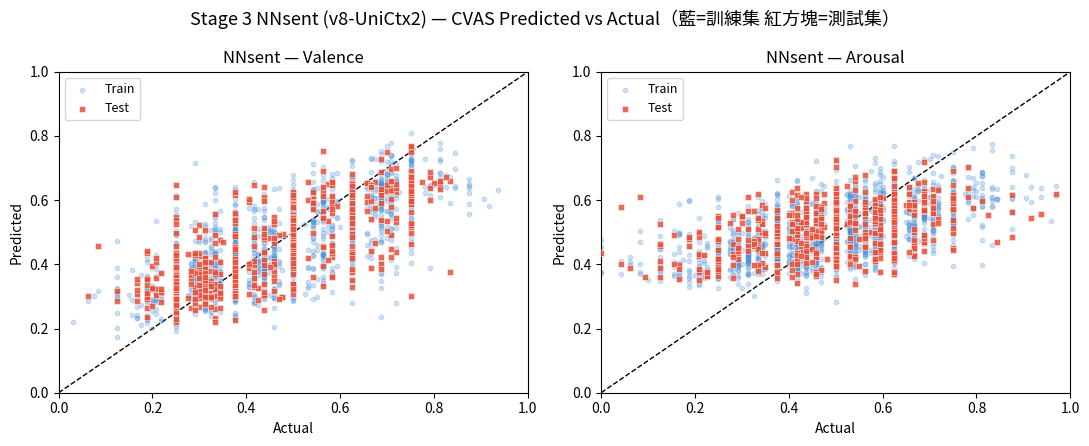

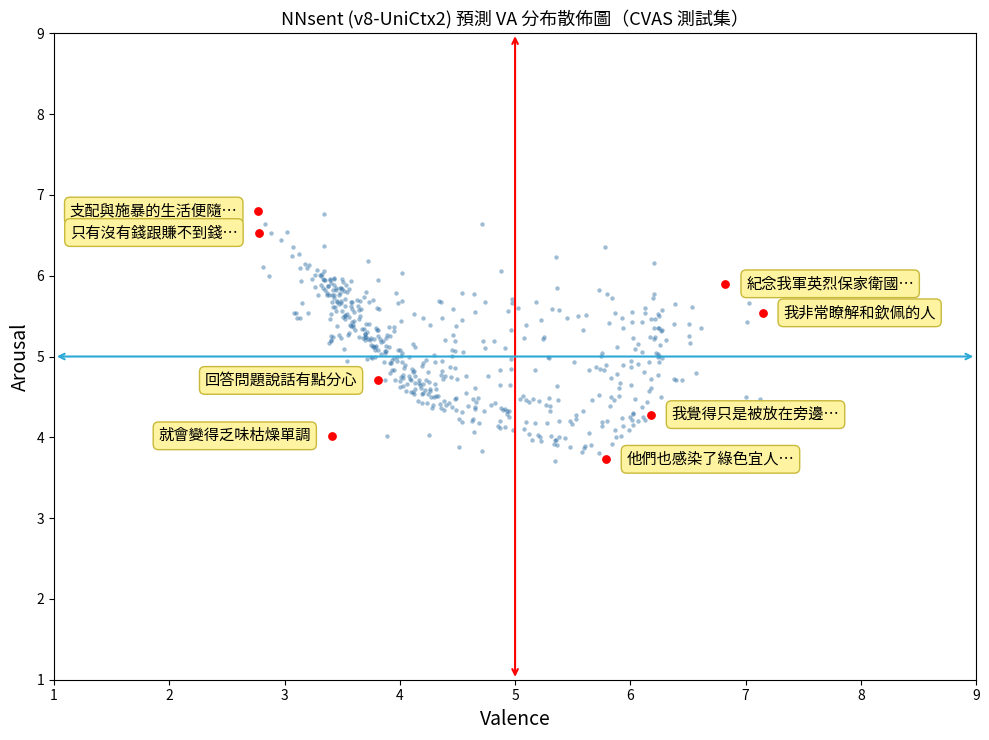

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle('Stage 3 NNsent (v8-UniCtx2) — CVAS Predicted vs Actual（藍=訓練集 紅方塊=測試集）', fontsize=13)
configs_sent = [
    (axes[0], pv_str, cvas_train_val, pv_ste, cvas_test_val, 'NNsent — Valence'),
    (axes[1], pa_str, cvas_train_aro, pa_ste, cvas_test_aro, 'NNsent — Arousal'),
]
for ax, ptr, gtr, pte, gte, title in configs_sent:
    ax.scatter(gtr, ptr, alpha=0.25, s=10, color='#4A90D9', label='Train', zorder=2)
    ax.scatter(gte, pte, alpha=0.85, s=20, color='#E8503A', marker='s',
               edgecolors='white', linewidths=0.4, label='Test', zorder=3)
    ax.plot([0, 1], [0, 1], 'k--', linewidth=1, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel('Actual'); ax.set_ylabel('Predicted')
    ax.set_title(title); ax.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

plot_va_scatter(pv_ste, pa_ste, [s['sentence'] for s in cvas_test_samples],
                'NNsent (v8-UniCtx2) 預測 VA 分布散佈圖（CVAS 測試集）', savepath='nnsent_unictx2_va_scatter.png')

### 14.6 哪些詞有幫助、哪些沒作用：Leave-One-Out 消融 + 每步貢獻度排行榜

作法同 v7 / v8：對每個 span 輪流整個拿掉（遞迴鏈，後面步驟的狀態會跟著變），重跑一次 NNsent，比較整句 VA 的變化 `ΔV / ΔA`。
因為 adapter 對每個 span 獨立計算，拿掉某個 span 只要把 `ctx` / `meta` 那一列刪掉，不需要重跑 BERT。
依 `seen_state`（seen / unseen_lex / oov）分組比較平均 `impact`，看「NNword 沒看過的詞」對整句 VA 有沒有貢獻。

In [38]:
@torch.no_grad()
def _nnsent_forward(ctx, meta):
    v, a, steps = model_sent(ctx, meta)
    return v.item(), a.item(), steps


@torch.no_grad()
def compute_span_importance(sample):
    """
    對一個樣本計算每個 span 的：
      contrib_v/contrib_a — NNsent 該步驟對句子狀態的貢獻強度（0.5=沒影響）
      delta_v/delta_a     — Leave-One-Out：把這個 span 拿掉後，整句最終 VA 的變化量
      impact              — sqrt(delta_v^2 + delta_a^2)
    """
    model_sent.eval()
    ctx, meta, infos = sample['ctx'], sample['meta'], sample['span_infos']
    n = len(infos)
    full_v, full_a, steps = _nnsent_forward(ctx, meta)

    results = []
    for i in range(n):
        if n == 1:
            loo_v, loo_a = 0.5, 0.5          # 只有一個 span，拿掉後視為中性
        else:
            keep = [j for j in range(n) if j != i]
            loo_v, loo_a, _ = _nnsent_forward(ctx[keep], meta[keep])
        dv, da = full_v - loo_v, full_a - loo_a
        results.append({
            'span_text': infos[i]['span_text'], 'core_word': infos[i]['core_word'],
            'modifier': infos[i]['modifier'], 'hit': infos[i]['hit'],
            'kind': infos[i]['kind'], 'seen_state': infos[i]['seen_state'],
            'contrib_v': float(steps[i][0]), 'contrib_a': float(steps[i][1]),
            'delta_v': float(dv), 'delta_a': float(da),
            'impact': float(np.sqrt(dv ** 2 + da ** 2)),
        })
    return full_v, full_a, results


print('compute_span_importance 定義完成')

compute_span_importance 定義完成


#### 全測試集彙整：資料驅動的「有幫助 / 普通 / 沒作用」門檻

In [39]:
print('對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...')
all_span_rows = []
for s in cvas_test_samples:
    _, _, span_results = compute_span_importance(s)
    for r in span_results:
        r['sentence'] = s['sentence']
        all_span_rows.append(r)

span_df = pd.DataFrame(all_span_rows)
span_df['contrib'] = (span_df['contrib_v'] + span_df['contrib_a']) / 2
print(f'共分析 {len(span_df)} 個 span（來自 {len(cvas_test_samples)} 個測試句子）')

q_low, q_high = span_df['impact'].quantile([0.33, 0.67])


def label_usefulness(impact):
    if impact >= q_high:
        return '有幫助'
    if impact <= q_low:
        return '沒作用'
    return '普通'


span_df['usefulness'] = span_df['impact'].apply(label_usefulness)
print(f'\nimpact 三分位門檻: 33%={q_low:.4f}  67%={q_high:.4f}')
print(span_df['usefulness'].value_counts())

print('\n=== 依「看過 / 沒看過」分組：平均對整句 VA 的貢獻 ===')
seen_rank = (span_df.groupby('seen_state')
             .agg(n=('impact', 'size'), mean_impact=('impact', 'mean'), mean_contrib=('contrib', 'mean'),
                  frac_useful=('usefulness', lambda x: (x == '有幫助').mean())))
print(seen_rank.to_string())
print('  seen=NNword 訓練看過；unseen_lex=在 CVAW 但 NNword 沒看過（驗證詞／測試詞）；oov=完全不在 CVAW（OOV_SPANS=True 才會有）')

對整個 CVAS 測試集跑 Leave-One-Out 消融（只重跑 NNsent，很快）...
共分析 642 個 span（來自 517 個測試句子）

impact 三分位門檻: 33%=0.0902  67%=0.1438
usefulness
普通     218
有幫助    212
沒作用    212
Name: count, dtype: int64

=== 依「看過 / 沒看過」分組：平均對整句 VA 的貢獻 ===
              n  mean_impact  mean_contrib  frac_useful
seen_state                                             
fallback     52     0.136468      0.478399     0.326923
seen        411     0.117603      0.516615     0.338200
unseen_lex  179     0.115434      0.506479     0.312849
  seen=NNword 訓練看過；unseen_lex=在 CVAW 但 NNword 沒看過（驗證詞／測試詞）；oov=完全不在 CVAW（OOV_SPANS=True 才會有）


#### 依「情感詞（核心詞）」與「修飾詞」分組的重要性排行榜

In [40]:
print('=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===')
core_rank = (
    span_df[span_df['core_word'].notna()]
    .groupby('core_word')
    .agg(n=('impact', 'size'), mean_impact=('impact', 'mean'), mean_contrib=('contrib', 'mean'),
         mean_dV=('delta_v', 'mean'), mean_dA=('delta_a', 'mean'), seen_state=('seen_state', 'first'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print('\n【最有幫助的情感詞（平均 impact 最高，前 20）】')
print(core_rank.head(20).to_string())
print('\n【幾乎沒作用的情感詞（平均 impact 最低，前 20）】')
print(core_rank.tail(20).sort_values('mean_impact').to_string())

print('\n=== 依「修飾詞」分組：平均對整句 VA 的貢獻 ===')
mod_rank = (
    span_df[span_df['modifier'].notna()]
    .groupby('modifier')
    .agg(n=('impact', 'size'), mean_impact=('impact', 'mean'), mean_contrib=('contrib', 'mean'),
         mean_dV=('delta_v', 'mean'), mean_dA=('delta_a', 'mean'))
    .query('n >= 2')
    .sort_values('mean_impact', ascending=False)
)
print(mod_rank.to_string())

core_rank.to_csv('cvas_unictx2_core_word_importance.csv', encoding='utf-8-sig')
mod_rank.to_csv('cvas_unictx2_modifier_importance.csv', encoding='utf-8-sig')
span_df.to_csv('cvas_unictx2_span_importance_raw.csv', index=False, encoding='utf-8-sig')
print('\n已輸出：cvas_unictx2_core_word_importance.csv / cvas_unictx2_modifier_importance.csv / cvas_unictx2_span_importance_raw.csv')

=== 依「情感詞（核心詞）」分組：平均對整句 VA 的貢獻 ===

【最有幫助的情感詞（平均 impact 最高，前 20）】
           n  mean_impact  mean_contrib   mean_dV   mean_dA  seen_state
core_word                                                              
造謠         2     0.173274      0.488850 -0.150070  0.076607        seen
壓迫         2     0.170548      0.494686 -0.145318  0.088971  unseen_lex
厭煩         2     0.149882      0.494175 -0.116182  0.091324        seen
殘酷         2     0.128388      0.499823 -0.121497  0.039439  unseen_lex
惡行         2     0.115805      0.508313 -0.082179  0.081111  unseen_lex
嚴重         2     0.115774      0.505281 -0.078176  0.084919        seen
東西         3     0.101226      0.453355 -0.090302  0.023554        seen
下降         3     0.096310      0.405680 -0.076640 -0.058206        seen
穩定         2     0.093624      0.524866  0.078318 -0.051091        seen
黑暗         2     0.090339      0.450855 -0.036553 -0.076707        seen
不能         3     0.088944      0.459162 -0.081685  0.023215  unseen_le

#### 單句 Demo：逐 span 列出 contribution + LOO 貢獻 + 有幫助/沒作用 標籤

In [41]:
@torch.no_grad()
def predict_sentence_with_importance(sentence, verbose=True):
    model_word.eval(); model_mod.eval(); model_sent.eval()
    sample = build_unified_sample(sentence)
    full_v, full_a, span_results = compute_span_importance(sample)

    fv9 = round(full_v * 8 + 1, 3)
    fa9 = round(full_a * 8 + 1, 3)
    pol = '正向' if full_v > 0.625 else ('負向' if full_v < 0.375 else '中性')
    act = '高喚起' if full_a > 0.625 else ('低喚起' if full_a < 0.375 else '中喚起')

    if verbose:
        print(f'\n句子：「{sentence}」')
        print(f'整句 VA（1-9）→ Valence={fv9}  Arousal={fa9}  [{pol}/{act}]\n')
        print(f'{"span":14s} {"kind":8s} {"狀態":10s} {"contrib":>8} {"DV":>8} {"DA":>8} {"impact":>8}  判斷')
        print('-' * 80)
        for r in sorted(span_results, key=lambda x: -x['impact']):
            tag = label_usefulness(r['impact'])
            contrib_disp = (r['contrib_v'] + r['contrib_a']) / 2
            print(f'{r["span_text"]:14s} {r["kind"]:8s} {r["seen_state"]:10s} {contrib_disp:8.3f} '
                  f'{r["delta_v"]:8.4f} {r["delta_a"]:8.4f} {r["impact"]:8.4f}  {tag}')
    return fv9, fa9, span_results


print('\n=== 句子推論 + 逐詞重要性 Demo ===')
for s in _demo_sents:
    predict_sentence_with_importance(s)


=== 句子推論 + 逐詞重要性 Demo ===

句子：「這次旅行真的非常開心，風景美極了！」
整句 VA（1-9）→ Valence=6.5  Arousal=5.654  [正向/中喚起]

span           kind     狀態          contrib       DV       DA   impact  判斷
--------------------------------------------------------------------------------
非常開心           lex      seen          0.732   0.1875   0.0817   0.2046  有幫助

句子：「主治醫師強調血液透析，家屬卻遲遲無法達到共識。」
整句 VA（1-9）→ Valence=4.707  Arousal=4.229  [中性/中喚起]

span           kind     狀態          contrib       DV       DA   impact  判斷
--------------------------------------------------------------------------------
達到             lex      seen          0.497   0.0589  -0.0411   0.0718  沒作用
無法             lex      unseen_lex    0.435  -0.0558  -0.0038   0.0559  沒作用

句子：「視病如親，讓我十分的動容。」
整句 VA（1-9）→ Valence=5.855  Arousal=5.178  [中性/中喚起]

span           kind     狀態          contrib       DV       DA   impact  判斷
--------------------------------------------------------------------------------
視病如親，讓我十分的動容。  fallback fallback      0.627   0.1